<!-- # Needed functions -->

In [1]:
import os
import sys
from pathlib import Path
import logging
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import oemof.solph as solph
from oemof.solph import (
    EnergySystem, Bus, Flow, Model,
    Investment, processing,
)
from oemof.solph.components import Source, Sink, Converter

PROJECT_DIR = Path.cwd().expanduser().resolve()
for candidate in (PROJECT_DIR, *PROJECT_DIR.parents):
    if (candidate / "Demand profiles_heating.xlsx").is_file() and (candidate / "helpers.py").is_file():
        PROJECT_DIR = candidate
        break
else:
    raise FileNotFoundError("Could not locate MJ2505_Project. Open the notebook from the project folder or a subfolder.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from helpers import LCOH, epc

OUTPUT_DIR = PROJECT_DIR / "Step3_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(level=logging.INFO)
plt.rcParams["figure.dpi"] = 110

print("Imports OK.")

Imports OK.


In [2]:
# ══════════════════════════════════════════════════════════════════
# EDIT ONLY THIS CELL
# ══════════════════════════════════════════════════════════════════
EXCEL_FILE  = PROJECT_DIR / "Demand profiles_heating.xlsx"
SHEET_NAME  = 0
TIME_COL    = None
DEMAND_UNIT = "kW"
YEAR        = 2024

SELECTED_PROFILES = [2, 4, 10, 16, 22, 3, 5, 6, 23, 28]

# Prices — match Step 2
ELECTRICITY_PRICE = 82.5   # DK2 2025 annual average [€/MWh]
BIOMASS_PRICE     = 35.0   # wood chips [€/MWh]
GAS_PRICE         = 50.0   # natural gas [€/MWh]

# Step 2 producer capacities [kW] — used as Investment maximum
P1_CAP = 400.0   # wood-chip boiler
P2_CAP = 400.0   # gas boiler
P3_CAP = 300.0   # waste-heat HP
P4_CAP = 300.0   # air-source HP
P5_CAP = 300.0   # electric boiler

# Annualisation — must match Step 2 (5 %, 30 y)
INTEREST_RATE = 0.05
LIFE_YEARS    = 30

In [3]:
# ── Load Excel ──────────────────────────────────────────────────
raw = pd.read_excel(EXCEL_FILE, sheet_name=SHEET_NAME)
print("Excel shape:", raw.shape)
print("Columns:", list(raw.columns)[:8], "...")

# ── Time index ──────────────────────────────────────────────────
if TIME_COL is not None and TIME_COL in raw.columns:
    raw[TIME_COL] = pd.to_datetime(raw[TIME_COL])
    raw = raw.set_index(TIME_COL).sort_index()
    time_index = raw.index
else:
    n = len(raw)
    if n not in (8760, 8784):
        raise ValueError(
            f"Expected 8760 or 8784 rows, got {n}. "
            "Check the file or provide TIME_COL."
        )
    time_index = pd.date_range(f"{YEAR}-01-01", periods=n, freq="h")
    raw.index = time_index

# ── Unit scale → MW ─────────────────────────────────────────────
scale = {"MW": 1.0, "kW": 0.001, "W": 1e-6}[DEMAND_UNIT]

# ── Select the 10 profiles ──────────────────────────────────────
selected_cols = [
    raw.columns[p] if isinstance(p, int) else p
    for p in SELECTED_PROFILES
]
df_sel = raw[selected_cols].copy()

if df_sel.isna().any().any():
    print("Warning: NaNs found — forward-filling.")
    df_sel = df_sel.ffill().fillna(0)

df_sel = df_sel * scale

# ── Aggregate ───────────────────────────────────────────────────
heat_demand = df_sel.sum(axis=1)
heat_demand.name = "heat_demand"

# Keep exactly 8760 hours
heat_demand = heat_demand.iloc[:8760]
heat_demand.index = pd.date_range(
    heat_demand.index[0], periods=8760, freq="h"
)

print(f"\nRows:                  {len(heat_demand)}")
print(f"Annual demand [MWh]:   {heat_demand.sum():,.2f}")
print(f"Peak demand [MW]:      {heat_demand.max():,.4f}")
print(f"Full-load hours [h]:   {heat_demand.sum()/heat_demand.max():,.0f}")

# ── Step 2 consistency check ───────────────────────────────────
assert abs(heat_demand.sum() - 6831.13) < 1.0, \
    f"Annual demand {heat_demand.sum():.2f} MWh ≠ Step 2's 6831.13 MWh"
assert abs(heat_demand.max() - 1.3542) < 0.01, \
    f"Peak {heat_demand.max():.4f} MW ≠ Step 2's 1.3542 MW"
print("Step 2 demand match ✓")

Excel shape: (8760, 51)
Columns: ['Time', 'Load 1', 'Load 2', 'Load 3', 'Load 4', 'Load 5', 'Load 6', 'Load 7'] ...

Rows:                  8760
Annual demand [MWh]:   6,831.13
Peak demand [MW]:      1.3542
Full-load hours [h]:   5,044
Step 2 demand match ✓


In [4]:
# ── Prices (constant, matching Step 2) ─────────────────────────
prices = pd.Series(ELECTRICITY_PRICE, index=heat_demand.index, name="electricity_price")
prices.name = "electricity_price"
print(f"Constant electricity price: {ELECTRICITY_PRICE} €/MWh")
print(f"Constant biomass price:     {BIOMASS_PRICE} €/MWh")
print(f"Constant gas price:         {GAS_PRICE} €/MWh")

Constant electricity price: 82.5 €/MWh
Constant biomass price:     35.0 €/MWh
Constant gas price:         50.0 €/MWh


In [5]:
df = pd.DataFrame(index=heat_demand.index)
df["heat_demand"]       = heat_demand.values
df["electricity_price"] = ELECTRICITY_PRICE
df["biomass_price"]     = BIOMASS_PRICE
df["gas_price"]         = GAS_PRICE

print(df.describe().T[["mean", "min", "max"]])
df.to_csv(OUTPUT_DIR / "step3_input_data.csv")
print(f"\nSaved: {OUTPUT_DIR}/step3_input_data.csv")

                       mean        min        max
heat_demand         0.77981   0.510798   1.354177
electricity_price  82.50000  82.500000  82.500000
biomass_price      35.00000  35.000000  35.000000
gas_price          50.00000  50.000000  50.000000

Saved: C:\Users\Jeffery\Desktop\Opt proj 2\Step3_results/step3_input_data.csv


In [6]:
es = EnergySystem(timeindex=df.index, infer_last_interval=True)

b_heat    = Bus(label="heat_bus")
b_elec    = Bus(label="elec_bus")
b_biomass = Bus(label="biomass_bus")
b_gas     = Bus(label="gas_bus")
b_waste   = Bus(label="waste_heat_bus")

es.add(b_heat, b_elec, b_biomass, b_gas, b_waste)

In [7]:
# ── Sources ─────────────────────────────────────────────────────
es.add(Source(
    label="electricity_grid",
    outputs={b_elec: Flow(variable_costs=df["electricity_price"])},
))
es.add(Source(
    label="biomass_fuel",
    outputs={b_biomass: Flow(variable_costs=df["biomass_price"])},
))
es.add(Source(
    label="gas_fuel",
    outputs={b_gas: Flow(variable_costs=df["gas_price"])},
))
es.add(Source(
    label="waste_heat_source",
    outputs={b_waste: Flow(variable_costs=0.0)},
))

# ── Sink ────────────────────────────────────────────────────────
es.add(Sink(
    label="heat_demand",
    inputs={b_heat: Flow(
        nominal_value=df["heat_demand"].max(),
        fix=df["heat_demand"] / df["heat_demand"].max(),
    )},
))

c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:182: FutureWarning: For backward compatibility, the option nominal_value overwrites the option nominal_capacity. Both options cannot be set at the same time.
  warn(msg, FutureWarning)


In [8]:
units = ["wood_chip_boiler", "gas_boiler", "waste_heat_hp",
         "air_source_hp", "electric_boiler"]

In [9]:
import os
import sys
from pathlib import Path

# 強制將 Anaconda 裡的 CBC 求解器路徑加入系統
cbc_folder = Path(sys.prefix) / "Library" / "bin"
if (cbc_folder / "cbc.exe").is_file():
    os.environ["PATH"] = str(cbc_folder) + os.pathsep + os.environ.get("PATH", "")
    print("✅ 成功找到 cbc.exe 並加入系統路徑！")
else:
    print("❌ 找不到 cbc.exe，代表剛剛的求解器其實沒有安裝成功。")

✅ 成功找到 cbc.exe 並加入系統路徑！


In [10]:
# ── Step 2 technology parameters ────────────────────────────────
# Implied heat costs must equal producer_assumptions.csv × 1000 (€/MWh_th)

ETA_WCB,  CAPEX_WCB,  VOM_WCB,  MAX_WCB  = 0.89, 300_000, 3.00, P1_CAP/1000.0
ETA_GB,   CAPEX_GB,   VOM_GB,   MAX_GB   = 0.93, 120_000, 2.00, P2_CAP/1000.0
COP_WH,   CAPEX_WH,   VOM_WH,   MAX_WH   = 3.10, 400_000, 3.07, P3_CAP/1000.0
COP_ASHP, CAPEX_ASHP, VOM_ASHP, MAX_ASHP = 2.75, 600_000, 0.86, P4_CAP/1000.0
ETA_EB,   CAPEX_EB,   VOM_EB,   MAX_EB   = 0.99, 150_000, 0.95, P5_CAP/1000.0

# ── Local annualisation helper (5 %, 30 y, matches Step 2) ─────
CRF = INTEREST_RATE * (1 + INTEREST_RATE)**LIFE_YEARS / \
      ((1 + INTEREST_RATE)**LIFE_YEARS - 1)

def epc_30(capex_per_MW):
    """€/MW → €/MW/yr at 5 %, 30 years."""
    return capex_per_MW * CRF

# ── 1. Wood-chip boiler (P1) ───────────────────────────────────
es.add(Converter(
    label="wood_chip_boiler",
    inputs={b_biomass: Flow()},
    outputs={b_heat: Flow(
        nominal_value=Investment(ep_costs=epc_30(CAPEX_WCB), maximum=MAX_WCB),
        variable_costs=VOM_WCB,
    )},
    conversion_factors={b_biomass: ETA_WCB},
))

# ── 2. Natural-gas boiler (P2) ─────────────────────────────────
es.add(Converter(
    label="gas_boiler",
    inputs={b_gas: Flow()},
    outputs={b_heat: Flow(
        nominal_value=Investment(ep_costs=epc_30(CAPEX_GB), maximum=MAX_GB),
        variable_costs=VOM_GB,
    )},
    conversion_factors={b_gas: ETA_GB},
))

# ── 3. Waste-heat HP (P3) ──────────────────────────────────────
es.add(Converter(
    label="waste_heat_hp",
    inputs={b_waste: Flow(), b_elec: Flow()},
    outputs={b_heat: Flow(
        nominal_value=Investment(ep_costs=epc_30(CAPEX_WH), maximum=MAX_WH),
        variable_costs=VOM_WH,
    )},
    conversion_factors={
        b_waste: (COP_WH - 1) / COP_WH,
        b_elec:  1 / COP_WH,
    },
))

# ── 4. Air-source HP (P4) ──────────────────────────────────────
es.add(Converter(
    label="air_source_hp",
    inputs={b_elec: Flow()},
    outputs={b_heat: Flow(
        nominal_value=Investment(ep_costs=epc_30(CAPEX_ASHP), maximum=MAX_ASHP),
        variable_costs=VOM_ASHP,
    )},
    conversion_factors={b_elec: 1 / COP_ASHP},
))

# ── 5. Electric boiler (P5) ────────────────────────────────────
es.add(Converter(
    label="electric_boiler",
    inputs={b_elec: Flow()},
    outputs={b_heat: Flow(
        nominal_value=Investment(ep_costs=epc_30(CAPEX_EB), maximum=MAX_EB),
        variable_costs=VOM_EB,
    )},
    conversion_factors={b_elec: ETA_EB},
))

model = solph.Model(es)
model.solve(
    solver="cbc",
    solve_kwargs={"tee": True},
    cmdline_options={"ratioGap": "0.02"},
)

results = processing.results(model)
meta_results = processing.meta_results(model)
es.dump(str(OUTPUT_DIR), "step3_results.oemof")

print("\nSolved.")
print("Objective value:", meta_results["objective"])

Welcome to the CBC MILP Solver 
Version: 2.10.13 
Build Date: May 12 2026 

command line - c:\Users\Jeffery\anaconda3\envs\dhnx_env\Library\bin\cbc.exe -ratioGap 0.02 -printingOptions all -import C:\Users\Jeffery\AppData\Local\Temp\tmp71w_3y5i.pyomo.lp -stat=1 -solve -solu C:\Users\Jeffery\AppData\Local\Temp\tmp71w_3y5i.pyomo.soln (default strategy 1)
ratioGap was changed from 0 to 0.02
Option for printingOptions changed from normal to all
Presolve 52560 (-87605) rows, 43805 (-87605) columns and 131400 (-192730) elements
Statistics for presolved model


Problem has 52560 rows, 43805 columns (43805 with objective) and 131400 elements
Column breakdown:
43800 of type 0.0->inf, 5 of type 0.0->up, 0 of type lo->inf, 
0 of type lo->up, 0 of type free, 0 of type fixed, 
0 of type -inf->0.0, 0 of type -inf->up, 0 of type 0.0->1.0 
Row breakdown:
0 of type E 0.0, 0 of type E 1.0, 0 of type E -1.0, 
8760 of type E other, 0 of type G 0.0, 0 of type G 1.0, 
0 of type G other, 43800 of type L 0.0, 

INFO:root:Optimization successful.



Solved.
Objective value: 244254.2758943184


c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\network\energy_system.py:360: FutureWarning: Parameter 'dpath' will be removed in a future version. You can give the directory as part of the filename and set 'consider_dpath' to False to suppress this waring.
  warnings.warn(


In [11]:
capacities = {}
for u in units:
    cap = results[(es.groups[u], b_heat)]["scalars"].get("invest", 0.0)
    capacities[u] = cap
    print(f"{u:22s}: {cap:8.4f} MW_th")

# Slice solver sequences to the modeled hours; infer_last_interval may add a final endpoint.
N = len(df.index)
heat_out = pd.DataFrame(index=df.index)
for u in units:
    seq = results[(es.groups[u], b_heat)]["sequences"]["flow"].values
    if len(seq) == N:
        heat_out[u] = seq
    elif len(seq) == N + 1:
        heat_out[u] = seq[:N]
    else:
        raise ValueError(f"Unexpected flow length {len(seq)} (expected {N} or {N+1})")

heat_out["demand"] = df["heat_demand"].values
imbalance = (heat_out[units].sum(axis=1) - heat_out["demand"]).abs().max()
print(f"\nMax energy-balance error: {imbalance:.6f} MWh/h")

print("\nAnnual heat supplied per unit [MWh]:")
print(heat_out[units].sum().sort_values(ascending=False).round(2))

wood_chip_boiler      :   0.4000 MW_th
gas_boiler            :   0.3542 MW_th
waste_heat_hp         :   0.3000 MW_th
air_source_hp         :   0.3000 MW_th
electric_boiler       :   0.0000 MW_th

Max energy-balance error: 0.000000 MWh/h

Annual heat supplied per unit [MWh]:
waste_heat_hp       2628.00
air_source_hp       2591.12
wood_chip_boiler    1531.94
gas_boiler            80.07
electric_boiler        0.00
dtype: float64


In [12]:
# ── LCOH — correct call with raw CAPEX, n=30, matching Step 2 ──
spec_inv = {"wood_chip_boiler": CAPEX_WCB, "gas_boiler": CAPEX_GB,
            "waste_heat_hp":   CAPEX_WH,  "air_source_hp": CAPEX_ASHP,
            "electric_boiler": CAPEX_EB}
var_cost = {"wood_chip_boiler": VOM_WCB, "gas_boiler": VOM_GB,
            "waste_heat_hp":   VOM_WH,  "air_source_hp": VOM_ASHP,
            "electric_boiler": VOM_EB}

fuel_cost_hourly = {
    "wood_chip_boiler": (1/ETA_WCB)   * df["biomass_price"],
    "gas_boiler":       (1/ETA_GB)    * df["gas_price"],
    "waste_heat_hp":    ((COP_WH-1)/COP_WH) * 0.0
                        + (1/COP_WH)  * df["electricity_price"],
    "air_source_hp":    (1/COP_ASHP)  * df["electricity_price"],
    "electric_boiler":  (1/ETA_EB)    * df["electricity_price"],
}

# Raw (un-annualised) CAPEX in € — what LCOH() expects as its first argument
raw_capex = sum(capacities[u] * spec_inv[u] for u in units)
inv_cost  = raw_capex * CRF                     # €/yr, only used for printing

# Operating cost (fuel + VOM)
op_cost = 0.0
for u in units:
    op_cost += (heat_out[u] * fuel_cost_hourly[u]).sum()
    op_cost += heat_out[u].sum() * var_cost[u]

heat_produced = heat_out["demand"].sum()

# Correct call — pass raw CAPEX, matching 30-year asset life
lcoh = LCOH(raw_capex, op_cost, heat_produced,
            i=INTEREST_RATE, n=LIFE_YEARS)

print(f"Raw CAPEX:                  {raw_capex:>15,.0f} €")
print(f"Annualised investment cost: {inv_cost:>15,.0f} €/year")
print(f"Annual operating cost:      {op_cost:>15,.0f} €/year")
print(f"Annual heat delivered:      {heat_produced:>15,.0f} MWh")
print(f"LCOH:                       {lcoh:>15,.2f} €/MWh")

# Self-check — LCOH must equal (annualised capex + opex) / heat
_check = (inv_cost + op_cost) / heat_produced
assert abs(lcoh - _check) < 0.01, f"LCOH mismatch: {lcoh:.4f} vs {_check:.4f}"
print(f"LCOH self-check:            {_check:>15,.2f} €/MWh  ✓")

Raw CAPEX:                          462,501 €
Annualised investment cost:          30,086 €/year
Annual operating cost:              227,274 €/year
Annual heat delivered:                6,831 MWh
LCOH:                                 37.67 €/MWh
LCOH self-check:                      37.67 €/MWh  ✓


In [13]:
# ── Shares ─────────────────────────────────────────────────────
share = heat_out[units].sum() / heat_out[units].sum().sum()
print("Share of total heat supplied [%]:")
print((share * 100).round(2).sort_values(ascending=False))

# ── Peak output / installed capacity ───────────────────────────
print("\nPeak output / installed capacity [%]:")
for u in units:
    cap = capacities[u]
    ratio = 100 * heat_out[u].max() / cap if cap > 0 else float("nan")
    print(f"  {u:22s}: {ratio:6.2f}%")

# ── Operating cost breakdown ───────────────────────────────────
print("\nOperating cost per unit [€/year]:")
total_op = 0.0
for u in units:
    fuel = (heat_out[u] * fuel_cost_hourly[u]).sum()
    vom  = heat_out[u].sum() * var_cost[u]
    total_op += fuel + vom
    print(f"  {u:22s}: fuel {fuel:>10,.0f}  VOM {vom:>8,.0f}  total {fuel+vom:>10,.0f}")
print(f"  {'TOTAL':22s}: {total_op:>10,.0f}")

# ── Cross-step comparison with Step 2 ──────────────────────────
step2_shares = {
    "wood_chip_boiler": 22.73,
    "gas_boiler":        1.58,
    "waste_heat_hp":    38.04,
    "air_source_hp":    37.64,
    "electric_boiler":   0.00,
}
print("\nStep 2 vs Step 3 shares [%]:")
cmp = pd.DataFrame({
    "Step2": pd.Series(step2_shares),
    "Step3": (share * 100).round(2),
})
cmp["Δ"] = cmp["Step3"] - cmp["Step2"]
print(cmp.round(2))

Share of total heat supplied [%]:
waste_heat_hp       38.47
air_source_hp       37.93
wood_chip_boiler    22.43
gas_boiler           1.17
electric_boiler      0.00
dtype: float64

Peak output / installed capacity [%]:
  wood_chip_boiler      : 100.00%
  gas_boiler            : 100.00%
  waste_heat_hp         : 100.00%
  air_source_hp         : 100.00%
  electric_boiler       :    nan%

Operating cost per unit [€/year]:
  wood_chip_boiler      : fuel     60,245  VOM    4,596  total     64,841
  gas_boiler            : fuel      4,305  VOM      160  total      4,465
  waste_heat_hp         : fuel     69,939  VOM    8,068  total     78,007
  air_source_hp         : fuel     77,733  VOM    2,228  total     79,962
  electric_boiler       : fuel          0  VOM        0  total          0
  TOTAL                 :    227,274

Step 2 vs Step 3 shares [%]:
                  Step2  Step3     Δ
wood_chip_boiler  22.73  22.43 -0.30
gas_boiler         1.58   1.17 -0.41
waste_heat_hp     38.04  38.4

In [14]:
# ══════════════════════════════════════════════════════════════════
# Scenario A — DK2 hourly prices, flat COP  (self-contained)
# ══════════════════════════════════════════════════════════════════
import requests
import pandas as pd
import numpy as np
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# ── 1. Ensure prices_h exists (fetch DK2 if missing) ──────────
if "prices_h" not in dir():
    print("Fetching DK2 hourly spot prices from Energinet...")
    url = "https://api.energidataservice.dk/dataset/Elspotprices"
    params = {
        "start":  f"{YEAR}-01-01",
        "end":    f"{YEAR}-12-31",
        "filter": '{"PriceArea":["DK2"]}',
        "sort":   "HourUTC asc",
        "limit":  100000,
    }
    retry = Retry(total=5, backoff_factor=2,
                  status_forcelist=[429, 500, 502, 503, 504],
                  allowed_methods=["GET"], raise_on_status=False)
    session = requests.Session()
    session.mount("https://", HTTPAdapter(max_retries=retry))
    r = session.get(url, params=params, timeout=60)
    r.raise_for_status()
    records = r.json()["records"]
    prices_h = pd.DataFrame(records)
    prices_h["HourUTC"] = pd.to_datetime(prices_h["HourUTC"])
    prices_h = prices_h.set_index("HourUTC")["SpotPriceEUR"].sort_index()
    prices_h = prices_h.reindex(df.index).ffill().bfill()
    prices_h.name = "electricity_price_hourly"
    print(f"  Fetched {len(prices_h)} hourly prices "
          f"(mean {prices_h.mean():.2f} €/MWh)")
else:
    print(f"Using existing prices_h (mean {prices_h.mean():.2f} €/MWh)")

# ── 2. df_h with hourly prices ─────────────────────────────────
df_h = df.copy()
df_h["electricity_price"] = prices_h.values

# ── 3. Builder (self-contained) ────────────────────────────────
def build_es_h(df_in, tag="_h"):
    """Same 5-producer ES with flat COP; uses df_in prices."""
    es = EnergySystem(timeindex=df_in.index, infer_last_interval=True)
    b_heat    = Bus(label=f"heat_bus{tag}")
    b_elec    = Bus(label=f"elec_bus{tag}")
    b_biomass = Bus(label=f"biomass_bus{tag}")
    b_gas     = Bus(label=f"gas_bus{tag}")
    b_waste   = Bus(label=f"waste_heat_bus{tag}")
    es.add(b_heat, b_elec, b_biomass, b_gas, b_waste)
    es.add(Source(label=f"electricity_grid{tag}",
        outputs={b_elec: Flow(variable_costs=df_in["electricity_price"])}))
    es.add(Source(label=f"biomass_fuel{tag}",
        outputs={b_biomass: Flow(variable_costs=df_in["biomass_price"])}))
    es.add(Source(label=f"gas_fuel{tag}",
        outputs={b_gas: Flow(variable_costs=df_in["gas_price"])}))
    es.add(Source(label=f"waste_heat_source{tag}",
        outputs={b_waste: Flow(variable_costs=0.0)}))
    es.add(Sink(label=f"heat_demand{tag}",
        inputs={b_heat: Flow(
            nominal_value=df_in["heat_demand"].max(),
            fix=(df_in["heat_demand"] / df_in["heat_demand"].max()).values)}))
    es.add(Converter(label=f"wood_chip_boiler{tag}",
        inputs={b_biomass: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_WCB), maximum=MAX_WCB),
            variable_costs=VOM_WCB)},
        conversion_factors={b_biomass: ETA_WCB}))
    es.add(Converter(label=f"gas_boiler{tag}",
        inputs={b_gas: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_GB), maximum=MAX_GB),
            variable_costs=VOM_GB)},
        conversion_factors={b_gas: ETA_GB}))
    es.add(Converter(label=f"waste_heat_hp{tag}",
        inputs={b_waste: Flow(), b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_WH), maximum=MAX_WH),
            variable_costs=VOM_WH)},
        conversion_factors={b_waste: (COP_WH-1)/COP_WH, b_elec: 1/COP_WH}))
    es.add(Converter(label=f"air_source_hp{tag}",
        inputs={b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_ASHP), maximum=MAX_ASHP),
            variable_costs=VOM_ASHP)},
        conversion_factors={b_elec: 1/COP_ASHP}))
    es.add(Converter(label=f"electric_boiler{tag}",
        inputs={b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_EB), maximum=MAX_EB),
            variable_costs=VOM_EB)},
        conversion_factors={b_elec: ETA_EB}))
    return es, b_heat

print("build_es_h() ready.")

# ── 4. Solve ───────────────────────────────────────────────────
es_h, b_heat_h = build_es_h(df_h, tag="_h")
model_h = solph.Model(es_h)
model_h.solve(solver="cbc", solve_kwargs={"tee": False},
              cmdline_options={"ratioGap": "0.02"})
results_h = processing.results(model_h)

# ── 5. Extract ─────────────────────────────────────────────────
N = len(df_h)
heat_out_h = pd.DataFrame(index=df_h.index)
caps_h = {}
for u in units:
    label = f"{u}_h"
    seq = results_h[(es_h.groups[label], b_heat_h)]["sequences"]["flow"].values
    heat_out_h[u] = seq[:N]
    caps_h[u] = results_h[(es_h.groups[label], b_heat_h)]["scalars"].get("invest", 0.0)
heat_out_h["demand"] = df_h["heat_demand"].values

err_h = (heat_out_h[units].sum(axis=1) - heat_out_h["demand"]).abs().max()
print(f"Scenario A balance error: {err_h:.6f} MWh/h")

share_h = heat_out_h[units].sum() / heat_out_h[units].sum().sum() * 100

# ── 6. Costs ───────────────────────────────────────────────────
fuel_A = {
    "wood_chip_boiler": (1/ETA_WCB)  * df_h["biomass_price"],
    "gas_boiler":       (1/ETA_GB)   * df_h["gas_price"],
    "waste_heat_hp":    ((COP_WH-1)/COP_WH) * 0.0
                        + (1/COP_WH) * df_h["electricity_price"],
    "air_source_hp":    (1/COP_ASHP) * df_h["electricity_price"],
    "electric_boiler":  (1/ETA_EB)   * df_h["electricity_price"],
}
op_h = sum((heat_out_h[u]*fuel_A[u]).sum()
           + heat_out_h[u].sum()*var_cost[u] for u in units)
raw_capex_h = sum(caps_h[u] * spec_inv[u] for u in units)
lcoh_h = LCOH(raw_capex_h, op_h, heat_out_h["demand"].sum(),
              i=INTEREST_RATE, n=LIFE_YEARS)

print(f"\nScenario A results:")
print(f"  OPEX: {op_h:>10,.0f} €/yr")
print(f"  LCOH: {lcoh_h:>10.2f} €/MWh")
print(f"\nShares [%]:")
print(share_h.round(2).to_string())

heat_out_h.to_csv(OUTPUT_DIR / "step3_dispatch_hourly_prices.csv")
print("\nSaved: step3_dispatch_hourly_prices.csv")

Fetching DK2 hourly spot prices from Energinet...
  Fetched 8760 hourly prices (mean 70.97 €/MWh)
build_es_h() ready.


c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:182: FutureWarning: For backward compatibility, the option nominal_value overwrites the option nominal_capacity. Both options cannot be set at the same time.
  warn(msg, FutureWarning)
INFO:root:Optimization successful.


Scenario A balance error: 0.000000 MWh/h

Scenario A results:
  OPEX:    195,265 €/yr
  LCOH:      33.31 €/MWh

Shares [%]:
wood_chip_boiler    26.88
gas_boiler           3.20
waste_heat_hp       35.18
air_source_hp       29.62
electric_boiler      5.11

Saved: step3_dispatch_hourly_prices.csv


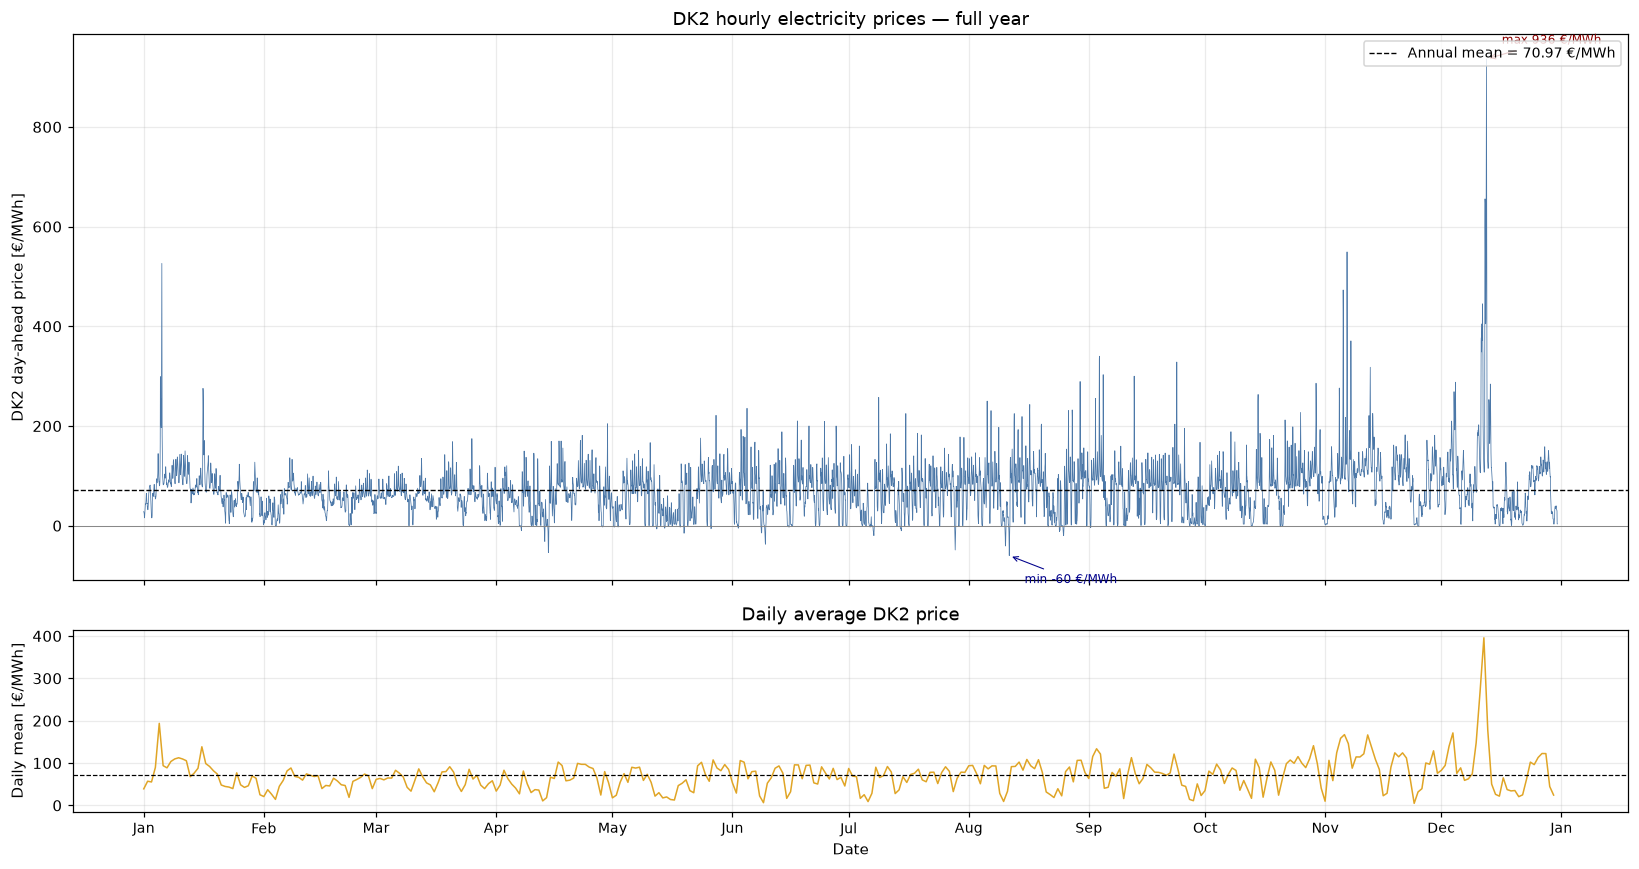

DK2 hourly price statistics:
  Mean:                 70.97 €/MWh
  Median:               68.85 €/MWh
  Std deviation:        52.23 €/MWh
  Min:                 -59.96 €/MWh
  Max:                 936.31 €/MWh
  P10:                   8.98 €/MWh
  P90:                 122.45 €/MWh
  Hours < 0 €/MWh:        275  (3.1 %)
  Hours < 30 €/MWh:      1759  (20.1 %)
  Hours > 100 €/MWh:     1927  (22.0 %)


In [15]:
# ══════════════════════════════════════════════════════════════════
# DK2 hourly electricity price — full year overview
# ══════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})

# ── Top panel: full-year price series ──────────────────────────
ax = axes[0]
ax.plot(prices_h.index, prices_h.values,
        color="#4c78a8", linewidth=0.5)
ax.axhline(prices_h.mean(), color="black", linestyle="--",
           linewidth=0.9, label=f"Annual mean = {prices_h.mean():.2f} €/MWh")
ax.axhline(0, color="grey", linewidth=0.6)

ax.set_ylabel("DK2 day-ahead price [€/MWh]")
ax.set_title("DK2 hourly electricity prices — full year")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.25)

# Annotate extremes
peak_idx = prices_h.idxmax()
min_idx  = prices_h.idxmin()
ax.annotate(f"max {prices_h.max():.0f} €/MWh",
            xy=(peak_idx, prices_h.max()),
            xytext=(10, 10), textcoords="offset points",
            fontsize=8, color="darkred",
            arrowprops=dict(arrowstyle="->", color="darkred", lw=0.7))
ax.annotate(f"min {prices_h.min():.0f} €/MWh",
            xy=(min_idx, prices_h.min()),
            xytext=(10, -18), textcoords="offset points",
            fontsize=8, color="darkblue",
            arrowprops=dict(arrowstyle="->", color="darkblue", lw=0.7))

# ── Bottom panel: daily mean ───────────────────────────────────
ax = axes[1]
daily_mean = prices_h.resample("D").mean()
ax.plot(daily_mean.index, daily_mean.values,
        color="#e0a526", linewidth=1.0)
ax.axhline(prices_h.mean(), color="black", linestyle="--", linewidth=0.8)
ax.set_ylabel("Daily mean [€/MWh]")
ax.set_xlabel("Date")
ax.set_title("Daily average DK2 price")
ax.grid(alpha=0.25)

# Month ticks
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.setp(ax.get_xticklabels(), fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "step3_dk2_price_overview.png"), dpi=150)
plt.show()

# ── Quick statistics for the report ───────────────────────────
print("DK2 hourly price statistics:")
print(f"  Mean:              {prices_h.mean():>8.2f} €/MWh")
print(f"  Median:            {prices_h.median():>8.2f} €/MWh")
print(f"  Std deviation:     {prices_h.std():>8.2f} €/MWh")
print(f"  Min:               {prices_h.min():>8.2f} €/MWh")
print(f"  Max:               {prices_h.max():>8.2f} €/MWh")
print(f"  P10:               {prices_h.quantile(0.10):>8.2f} €/MWh")
print(f"  P90:               {prices_h.quantile(0.90):>8.2f} €/MWh")
print(f"  Hours < 0 €/MWh:   {(prices_h < 0).sum():>8d}  "
      f"({(prices_h < 0).mean()*100:.1f} %)")
print(f"  Hours < 30 €/MWh:  {(prices_h < 30).sum():>8d}  "
      f"({(prices_h < 30).mean()*100:.1f} %)")
print(f"  Hours > 100 €/MWh: {(prices_h > 100).sum():>8d}  "
      f"({(prices_h > 100).mean()*100:.1f} %)")

T_out:  mean 8.50, min -10.82, max 27.44 °C
COP(T): mean 2.86, min 1.80, max 4.28
Hours < 0 °C: 1329


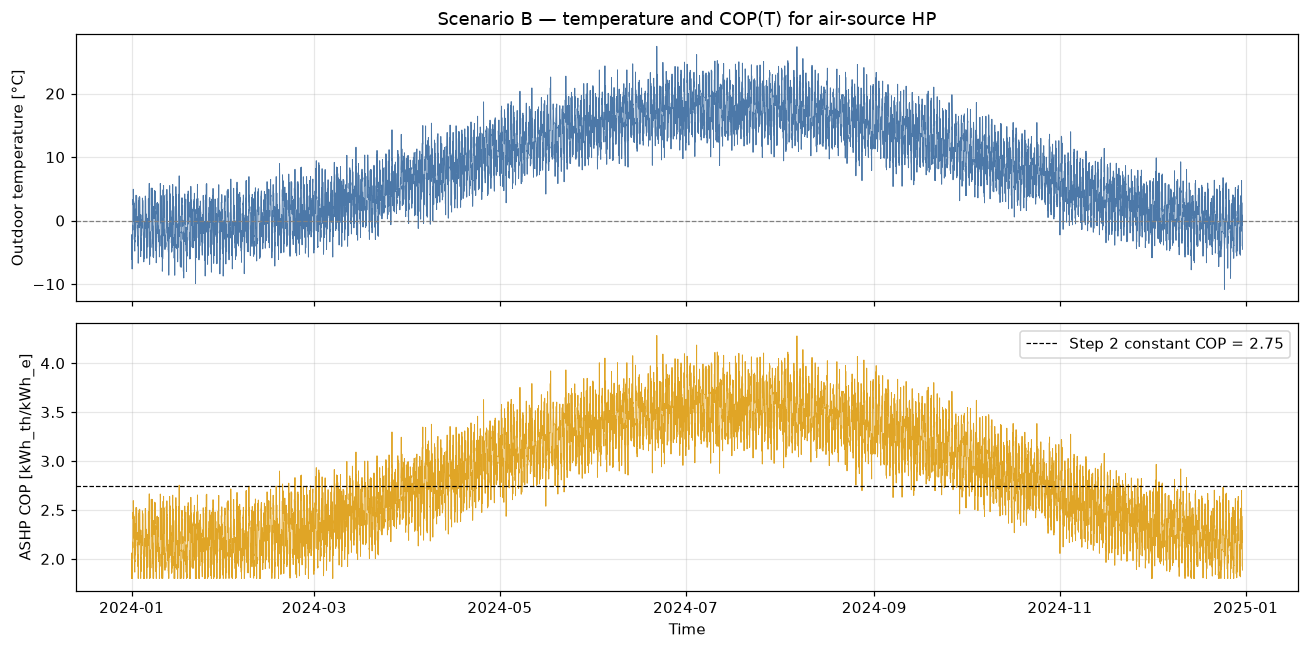


build_es_B() ready.


c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:182: FutureWarning: For backward compatibility, the option nominal_value overwrites the option nominal_capacity. Both options cannot be set at the same time.
  warn(msg, FutureWarning)
INFO:root:Optimization successful.


Scenario B balance error: 0.000000 MWh/h

Scenario B results:
  OPEX:    194,759 €/yr
  LCOH:      33.25 €/MWh

Shares [%]:
wood_chip_boiler    26.44
gas_boiler           3.65
waste_heat_hp       32.11
air_source_hp       32.69
electric_boiler      5.11

ASHP realised electricity price: 20.89 €/MWh

Saved: step3_dispatch_B_hourlycop.csv


In [16]:
# ══════════════════════════════════════════════════════════════════
# Scenario B — DK2 hourly prices + temperature-dependent COP
#              for air-source HP  (self-contained)
# ══════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ── 1. Ensure df_h exists (run Cell A first) ──────────────────
if "df_h" not in dir():
    raise RuntimeError("df_h not found. Run Scenario A cell first.")

# ── 2. Synthetic Copenhagen hourly temperature ────────────────
hours       = np.arange(len(df_h))
day_of_year = hours / 24.0
hour_of_day = hours % 24

T_annual = 8.5 - 9.5 * np.cos(2 * np.pi * (day_of_year - 15) / 365)
T_daily  = 3.5 * np.sin(2 * np.pi * (hour_of_day - 8) / 24)
rng = np.random.default_rng(42)
T_noise = rng.normal(0, 2.0, len(df_h))

T_out = T_annual + T_daily + T_noise
T_out = T_out - T_out.mean() + 8.5
T_out_series = pd.Series(T_out, index=df_h.index, name="T_out_C")

# COP(T) for air-source HP serving DH at 70/35 °C
COP_ASH_P = 2.75 + 0.075 * (T_out_series - 7.0)
COP_ASH_P = COP_ASH_P.clip(1.80, 5.00)
COP_ASH_P.name = "COP_ASHP_t"

print(f"T_out:  mean {T_out_series.mean():.2f}, "
      f"min {T_out_series.min():.2f}, max {T_out_series.max():.2f} °C")
print(f"COP(T): mean {COP_ASH_P.mean():.2f}, "
      f"min {COP_ASH_P.min():.2f}, max {COP_ASH_P.max():.2f}")
print(f"Hours < 0 °C: {(T_out_series < 0).sum()}")

# Optional plot
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(T_out_series.index, T_out_series.values, color="#4c78a8", lw=0.6)
axes[0].axhline(0, color="grey", ls="--", lw=0.8)
axes[0].set_ylabel("Outdoor temperature [°C]")
axes[0].set_title("Scenario B — temperature and COP(T) for air-source HP")
axes[0].grid(alpha=0.3)
axes[1].plot(COP_ASH_P.index, COP_ASH_P.values, color="#e0a526", lw=0.6)
axes[1].axhline(2.75, color="black", ls="--", lw=0.8,
                label="Step 2 constant COP = 2.75")
axes[1].set_ylabel("ASHP COP [kWh_th/kWh_e]")
axes[1].set_xlabel("Time")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step3_COP_ASHP_hourly.png", dpi=150)
plt.show()

# ── 3. Builder with time-varying ASHP COP ──────────────────────
def build_es_B(df_in, cop_ashp, tag="_B"):
    """Same 5-producer ES; ASHP conversion factor is time-varying 1/COP(T)."""
    es = EnergySystem(timeindex=df_in.index, infer_last_interval=True)
    b_heat    = Bus(label=f"heat_bus{tag}")
    b_elec    = Bus(label=f"elec_bus{tag}")
    b_biomass = Bus(label=f"biomass_bus{tag}")
    b_gas     = Bus(label=f"gas_bus{tag}")
    b_waste   = Bus(label=f"waste_heat_bus{tag}")
    es.add(b_heat, b_elec, b_biomass, b_gas, b_waste)
    es.add(Source(label=f"electricity_grid{tag}",
        outputs={b_elec: Flow(variable_costs=df_in["electricity_price"])}))
    es.add(Source(label=f"biomass_fuel{tag}",
        outputs={b_biomass: Flow(variable_costs=df_in["biomass_price"])}))
    es.add(Source(label=f"gas_fuel{tag}",
        outputs={b_gas: Flow(variable_costs=df_in["gas_price"])}))
    es.add(Source(label=f"waste_heat_source{tag}",
        outputs={b_waste: Flow(variable_costs=0.0)}))
    es.add(Sink(label=f"heat_demand{tag}",
        inputs={b_heat: Flow(
            nominal_value=df_in["heat_demand"].max(),
            fix=(df_in["heat_demand"] / df_in["heat_demand"].max()).values)}))
    es.add(Converter(label=f"wood_chip_boiler{tag}",
        inputs={b_biomass: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_WCB), maximum=MAX_WCB),
            variable_costs=VOM_WCB)},
        conversion_factors={b_biomass: ETA_WCB}))
    es.add(Converter(label=f"gas_boiler{tag}",
        inputs={b_gas: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_GB), maximum=MAX_GB),
            variable_costs=VOM_GB)},
        conversion_factors={b_gas: ETA_GB}))
    es.add(Converter(label=f"waste_heat_hp{tag}",
        inputs={b_waste: Flow(), b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_WH), maximum=MAX_WH),
            variable_costs=VOM_WH)},
        conversion_factors={b_waste: (COP_WH-1)/COP_WH, b_elec: 1/COP_WH}))
    # Air-source HP with time-varying COP
    es.add(Converter(label=f"air_source_hp{tag}",
        inputs={b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_ASHP), maximum=MAX_ASHP),
            variable_costs=VOM_ASHP)},
        conversion_factors={b_elec: 1/cop_ashp}))
    es.add(Converter(label=f"electric_boiler{tag}",
        inputs={b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_EB), maximum=MAX_EB),
            variable_costs=VOM_EB)},
        conversion_factors={b_elec: ETA_EB}))
    return es, b_heat

print("\nbuild_es_B() ready.")

# ── 4. Solve ───────────────────────────────────────────────────
es_B, b_heat_B = build_es_B(df_h, COP_ASH_P, tag="_B")
model_B = solph.Model(es_B)
model_B.solve(solver="cbc", solve_kwargs={"tee": False},
              cmdline_options={"ratioGap": "0.02"})
results_B = processing.results(model_B)

# ── 5. Extract ─────────────────────────────────────────────────
N = len(df_h)
heat_out_B = pd.DataFrame(index=df_h.index)
caps_B = {}
for u in units:
    label = f"{u}_B"
    seq = results_B[(es_B.groups[label], b_heat_B)]["sequences"]["flow"].values
    heat_out_B[u] = seq[:N]
    caps_B[u] = results_B[(es_B.groups[label], b_heat_B)]["scalars"].get("invest", 0.0)
heat_out_B["demand"] = df_h["heat_demand"].values

err_B = (heat_out_B[units].sum(axis=1) - heat_out_B["demand"]).abs().max()
print(f"Scenario B balance error: {err_B:.6f} MWh/h")

share_B = heat_out_B[units].sum() / heat_out_B[units].sum().sum() * 100

# ── 6. Costs (ASHP uses hourly COP) ────────────────────────────
fuel_B = {
    "wood_chip_boiler": (1/ETA_WCB)   * df_h["biomass_price"],
    "gas_boiler":       (1/ETA_GB)    * df_h["gas_price"],
    "waste_heat_hp":    ((COP_WH-1)/COP_WH) * 0.0
                        + (1/COP_WH)  * df_h["electricity_price"],
    "air_source_hp":    (1/COP_ASH_P) * df_h["electricity_price"],
    "electric_boiler":  (1/ETA_EB)    * df_h["electricity_price"],
}
op_B = sum((heat_out_B[u]*fuel_B[u]).sum()
           + heat_out_B[u].sum()*var_cost[u] for u in units)
raw_capex_B = sum(caps_B[u] * spec_inv[u] for u in units)
lcoh_B = LCOH(raw_capex_B, op_B, heat_out_B["demand"].sum(),
              i=INTEREST_RATE, n=LIFE_YEARS)

print(f"\nScenario B results:")
print(f"  OPEX: {op_B:>10,.0f} €/yr")
print(f"  LCOH: {lcoh_B:>10,.2f} €/MWh")
print(f"\nShares [%]:")
print(share_B.round(2).to_string())

# Realised electricity price of the ASHP under COP(T)
tot_ashp = heat_out_B["air_source_hp"].sum()
if tot_ashp > 0:
    ashp_real = (heat_out_B["air_source_hp"]
                 * (1/COP_ASH_P) * df_h["electricity_price"]).sum() / tot_ashp
    print(f"\nASHP realised electricity price: {ashp_real:.2f} €/MWh")

heat_out_B.to_csv(OUTPUT_DIR / "step3_dispatch_B_hourlycop.csv")
print("\nSaved: step3_dispatch_B_hourlycop.csv")

In [17]:
# ══════════════════════════════════════════════════════════════════
# Scenario C - DK2 hourly + Combined outage scenario (self-contained)
# ══════════════════════════════════════════════════════════════════
from oemof.solph import NonConvex

# ── Make sure dependencies exist ───────────────────────────────
# df_h (hourly prices) should have been created in the Sens. A cell
if "df_h" not in dir():
    if "prices_h" in dir():
        df_h = df.copy()
        df_h["electricity_price"] = prices_h.values
        print("df_h reconstructed from prices_h")
    else:
        raise RuntimeError("Neither df_h nor prices_h exists. Run the Sens. A cell first.")

# PLANNED and MAX_derated should have been defined earlier
if "PLANNED" not in dir() or "MAX_derated" not in dir():
    # Rebuild them (combined outage parameters)
    PLANNED_WEEKS = {
        "wood_chip_boiler": 2.6, "gas_boiler": 1.0,
        "waste_heat_hp":    1.0, "air_source_hp": 1.0, "electric_boiler": 0.5,
    }
    FORCED_RATE = {
        "wood_chip_boiler": 0.03, "gas_boiler": 0.01,
        "waste_heat_hp":    0.02, "air_source_hp": 0.02, "electric_boiler": 0.01,
    }
    MAX_derated = {
        "wood_chip_boiler": MAX_WCB  * (1 - FORCED_RATE["wood_chip_boiler"]),
        "gas_boiler":       MAX_GB   * (1 - FORCED_RATE["gas_boiler"]),
        "waste_heat_hp":    MAX_WH   * (1 - FORCED_RATE["waste_heat_hp"]),
        "air_source_hp":    MAX_ASHP * (1 - FORCED_RATE["air_source_hp"]),
        "electric_boiler":  MAX_EB   * (1 - FORCED_RATE["electric_boiler"]),
    }
    hours = np.arange(len(df))
    weeks = hours / (24 * 7)
    def planned_mask(start_week, n_weeks):
        avail = np.ones(len(df))
        in_outage = (weeks >= start_week) & (weeks < start_week + n_weeks)
        avail[in_outage] = 0.0
        return avail
    PLANNED = {
        "wood_chip_boiler": planned_mask(22.0, PLANNED_WEEKS["wood_chip_boiler"]),
        "electric_boiler":  planned_mask(24.7, PLANNED_WEEKS["electric_boiler"]),
        "gas_boiler":       planned_mask(25.3, PLANNED_WEEKS["gas_boiler"]),
        "waste_heat_hp":    planned_mask(26.4, PLANNED_WEEKS["waste_heat_hp"]),
        "air_source_hp":    planned_mask(27.5, PLANNED_WEEKS["air_source_hp"]),
    }
    print("PLANNED and MAX_derated rebuilt")

# ── Define the builder (idempotent — safe to redefine) ────────
def build_es_combined(df_in, avail_dict, derated_max, tag="_C"):
    """5-producer ES with both derated Investment.maximum AND
    time-varying planned outage masks on the heat output flows."""
    es = EnergySystem(timeindex=df_in.index, infer_last_interval=True)
    b_heat    = Bus(label=f"heat_bus{tag}")
    b_elec    = Bus(label=f"elec_bus{tag}")
    b_biomass = Bus(label=f"biomass_bus{tag}")
    b_gas     = Bus(label=f"gas_bus{tag}")
    b_waste   = Bus(label=f"waste_heat_bus{tag}")
    es.add(b_heat, b_elec, b_biomass, b_gas, b_waste)

    es.add(Source(label=f"electricity_grid{tag}",
        outputs={b_elec: Flow(variable_costs=df_in["electricity_price"])}))
    es.add(Source(label=f"biomass_fuel{tag}",
        outputs={b_biomass: Flow(variable_costs=df_in["biomass_price"])}))
    es.add(Source(label=f"gas_fuel{tag}",
        outputs={b_gas: Flow(variable_costs=df_in["gas_price"])}))
    es.add(Source(label=f"waste_heat_source{tag}",
        outputs={b_waste: Flow(variable_costs=0.0)}))
    es.add(Sink(label=f"heat_demand{tag}",
        inputs={b_heat: Flow(
            nominal_value=df_in["heat_demand"].max(),
            fix=(df_in["heat_demand"] / df_in["heat_demand"].max()).values)}))

    es.add(Converter(label=f"wood_chip_boiler{tag}",
        inputs={b_biomass: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_WCB),
                                     maximum=derated_max["wood_chip_boiler"]),
            variable_costs=VOM_WCB,
            max=avail_dict["wood_chip_boiler"])},
        conversion_factors={b_biomass: ETA_WCB}))
    es.add(Converter(label=f"gas_boiler{tag}",
        inputs={b_gas: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_GB),
                                     maximum=derated_max["gas_boiler"]),
            variable_costs=VOM_GB,
            max=avail_dict["gas_boiler"])},
        conversion_factors={b_gas: ETA_GB}))
    es.add(Converter(label=f"waste_heat_hp{tag}",
        inputs={b_waste: Flow(), b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_WH),
                                     maximum=derated_max["waste_heat_hp"]),
            variable_costs=VOM_WH,
            max=avail_dict["waste_heat_hp"])},
        conversion_factors={b_waste: (COP_WH-1)/COP_WH, b_elec: 1/COP_WH}))
    es.add(Converter(label=f"air_source_hp{tag}",
        inputs={b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_ASHP),
                                     maximum=derated_max["air_source_hp"]),
            variable_costs=VOM_ASHP,
            max=avail_dict["air_source_hp"])},
        conversion_factors={b_elec: 1/COP_ASHP}))
    es.add(Converter(label=f"electric_boiler{tag}",
        inputs={b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_EB),
                                     maximum=derated_max["electric_boiler"]),
            variable_costs=VOM_EB,
            max=avail_dict["electric_boiler"])},
        conversion_factors={b_elec: ETA_EB}))
    return es, b_heat

print("build_es_combined() ready.")

# ── Build and solve with hourly DK2 prices ────────────────────
es_Ch, b_heat_Ch = build_es_combined(df_h, PLANNED, MAX_derated, tag="_Ch")
model_Ch = solph.Model(es_Ch)
model_Ch.solve(solver="cbc", solve_kwargs={"tee": False},
               cmdline_options={"ratioGap": "0.02"})
results_Ch = processing.results(model_Ch)

# ── Extract ────────────────────────────────────────────────────
N = len(df_h)
heat_out_Ch = pd.DataFrame(index=df_h.index)
caps_Ch = {}
for u in units:
    label = f"{u}_Ch"
    seq = results_Ch[(es_Ch.groups[label], b_heat_Ch)]["sequences"]["flow"].values
    heat_out_Ch[u] = seq[:N]
    caps_Ch[u] = results_Ch[(es_Ch.groups[label], b_heat_Ch)]["scalars"].get("invest", 0.0)
heat_out_Ch["demand"] = df_h["heat_demand"].values

err_Ch = (heat_out_Ch[units].sum(axis=1) - heat_out_Ch["demand"]).abs().max()
print(f"Balance error: {err_Ch:.6f} MWh/h")

share_Ch = heat_out_Ch[units].sum() / heat_out_Ch[units].sum().sum() * 100

# ── Verification ───────────────────────────────────────────────
print("\nVerification:")
for u in units:
    idx = PLANNED[u] == 0
    if idx.any():
        during = heat_out_Ch[u][idx].max()
        print(f"  {u:22s}  planned max = {during:.6f}  "
              f"{'✓' if during < 1e-6 else '✗'}")
    peak = heat_out_Ch[u].max()
    ok = peak <= MAX_derated[u] + 1e-6
    print(f"  {u:22s}  peak = {peak:.4f} ≤ {MAX_derated[u]:.4f}  "
          f"{'✓' if ok else '✗'}")

# ── Costs (hourly electricity price flows into HP/EB) ─────────
fuel_Ch = {
    "wood_chip_boiler": (1/ETA_WCB)  * df_h["biomass_price"],
    "gas_boiler":       (1/ETA_GB)   * df_h["gas_price"],
    "waste_heat_hp":    ((COP_WH-1)/COP_WH) * 0.0
                        + (1/COP_WH) * df_h["electricity_price"],
    "air_source_hp":    (1/COP_ASHP) * df_h["electricity_price"],
    "electric_boiler":  (1/ETA_EB)   * df_h["electricity_price"],
}
op_Ch = sum((heat_out_Ch[u]*fuel_Ch[u]).sum()
            + heat_out_Ch[u].sum()*var_cost[u] for u in units)
raw_capex_Ch = sum(caps_Ch[u] * spec_inv[u] for u in units)
lcoh_Ch = LCOH(raw_capex_Ch, op_Ch, heat_out_Ch["demand"].sum(),
               i=INTEREST_RATE, n=LIFE_YEARS)

print(f"\nDK2 + Combined outage results:")
print(f"  OPEX: {op_Ch:>10,.0f} €/yr")
print(f"  LCOH: {lcoh_Ch:>10,.2f} €/MWh")
print(f"\nShares [%]:")
print(share_Ch.round(2).to_string())

heat_out_Ch.to_csv(OUTPUT_DIR / "step3_dispatch_combined_outage_hourly.csv")
print("\nSaved: step3_dispatch_combined_outage_hourly.csv")

PLANNED and MAX_derated rebuilt
build_es_combined() ready.


c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:182: FutureWarning: For backward compatibility, the option nominal_value overwrites the option nominal_capacity. Both options cannot be set at the same time.
  warn(msg, FutureWarning)
c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:221: FutureWarning: For backward compatibility, the option max overwrites the option maximum. Both options cannot be set at the same time.
  warn(msg, FutureWarning)
INFO:root:Optimization successful.


Balance error: 0.000000 MWh/h

Verification:
  wood_chip_boiler        planned max = 0.000000  ✓
  wood_chip_boiler        peak = 0.3880 ≤ 0.3880  ✓
  gas_boiler              planned max = 0.000000  ✓
  gas_boiler              peak = 0.3543 ≤ 0.3960  ✓
  waste_heat_hp           planned max = 0.000000  ✓
  waste_heat_hp           peak = 0.2940 ≤ 0.2940  ✓
  air_source_hp           planned max = 0.000000  ✓
  air_source_hp           peak = 0.2940 ≤ 0.2940  ✓
  electric_boiler         planned max = 0.000000  ✓
  electric_boiler         peak = 0.2915 ≤ 0.2970  ✓

DK2 + Combined outage results:
  OPEX:    197,905 €/yr
  LCOH:      33.70 €/MWh

Shares [%]:
wood_chip_boiler    26.57
gas_boiler           3.99
waste_heat_hp       34.11
air_source_hp       29.25
electric_boiler      6.08

Saved: step3_dispatch_combined_outage_hourly.csv


In [18]:
# ══════════════════════════════════════════════════════════════════
# Scenario D - DK2 hourly + Min-load scenario (self-contained)
# ══════════════════════════════════════════════════════════════════
from oemof.solph import NonConvex
import time

MIN_WCB = 0.30
MIN_GB  = 0.20

if "df_h" not in dir():
    raise RuntimeError("df_h not found. Run the Sens. A cell or the previous cell first.")

def build_es_minload(df_in, tag="_nlh"):
    es = EnergySystem(timeindex=df_in.index, infer_last_interval=True)
    b_heat    = Bus(label=f"heat_bus{tag}")
    b_elec    = Bus(label=f"elec_bus{tag}")
    b_biomass = Bus(label=f"biomass_bus{tag}")
    b_gas     = Bus(label=f"gas_bus{tag}")
    b_waste   = Bus(label=f"waste_heat_bus{tag}")
    es.add(b_heat, b_elec, b_biomass, b_gas, b_waste)
    es.add(Source(label=f"electricity_grid{tag}",
        outputs={b_elec: Flow(variable_costs=df_in["electricity_price"])}))
    es.add(Source(label=f"biomass_fuel{tag}",
        outputs={b_biomass: Flow(variable_costs=df_in["biomass_price"])}))
    es.add(Source(label=f"gas_fuel{tag}",
        outputs={b_gas: Flow(variable_costs=df_in["gas_price"])}))
    es.add(Source(label=f"waste_heat_source{tag}",
        outputs={b_waste: Flow(variable_costs=0.0)}))
    es.add(Sink(label=f"heat_demand{tag}",
        inputs={b_heat: Flow(
            nominal_value=df_in["heat_demand"].max(),
            fix=(df_in["heat_demand"] / df_in["heat_demand"].max()).values)}))
    es.add(Converter(label=f"wood_chip_boiler{tag}",
        inputs={b_biomass: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_WCB), maximum=MAX_WCB),
            variable_costs=VOM_WCB,
            nonconvex=NonConvex(), min=MIN_WCB, max=1.0)},
        conversion_factors={b_biomass: ETA_WCB}))
    es.add(Converter(label=f"gas_boiler{tag}",
        inputs={b_gas: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_GB), maximum=MAX_GB),
            variable_costs=VOM_GB,
            nonconvex=NonConvex(), min=MIN_GB, max=1.0)},
        conversion_factors={b_gas: ETA_GB}))
    es.add(Converter(label=f"waste_heat_hp{tag}",
        inputs={b_waste: Flow(), b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_WH), maximum=MAX_WH),
            variable_costs=VOM_WH)},
        conversion_factors={b_waste: (COP_WH-1)/COP_WH, b_elec: 1/COP_WH}))
    es.add(Converter(label=f"air_source_hp{tag}",
        inputs={b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_ASHP), maximum=MAX_ASHP),
            variable_costs=VOM_ASHP)},
        conversion_factors={b_elec: 1/COP_ASHP}))
    es.add(Converter(label=f"electric_boiler{tag}",
        inputs={b_elec: Flow()},
        outputs={b_heat: Flow(
            nominal_value=Investment(ep_costs=epc_30(CAPEX_EB), maximum=MAX_EB),
            variable_costs=VOM_EB)},
        conversion_factors={b_elec: ETA_EB}))
    return es, b_heat

es_nl, b_heat_nl = build_es_minload(df_h, tag="_nlh")
model_nl = solph.Model(es_nl)

print("Solving min-load MILP with DK2 hourly prices...")
t0 = time.time()
model_nl.solve(solver="cbc", solve_kwargs={"tee": False},
               cmdline_options={"ratioGap": "0.05"})
print(f"Solved in {(time.time()-t0)/60:.1f} min.")

results_nl = processing.results(model_nl)
heat_out_nl = pd.DataFrame(index=df_h.index)
caps_nl = {}
for u in units:
    label = f"{u}_nlh"
    seq = results_nl[(es_nl.groups[label], b_heat_nl)]["sequences"]["flow"].values
    heat_out_nl[u] = seq[:N]
    caps_nl[u] = results_nl[(es_nl.groups[label], b_heat_nl)]["scalars"].get("invest", 0.0)
heat_out_nl["demand"] = df_h["heat_demand"].values

err_nl = (heat_out_nl[units].sum(axis=1) - heat_out_nl["demand"]).abs().max()
print(f"Balance error: {err_nl:.6f} MWh/h")

share_nl = heat_out_nl[units].sum() / heat_out_nl[units].sum().sum() * 100

for u, m in [("wood_chip_boiler", MIN_WCB), ("gas_boiler", MIN_GB)]:
    on = heat_out_nl[u] > 1e-6
    if on.any():
        min_obs = heat_out_nl[u][on].min()
        threshold = caps_nl[u] * m
        ok = min_obs >= threshold * (1 - 1e-3)
        print(f"  {u:22s}: min = {min_obs:.4f} ≥ {threshold:.4f}  "
              f"{'✓' if ok else '✗'}")

fuel_nl = {
    "wood_chip_boiler": (1/ETA_WCB)  * df_h["biomass_price"],
    "gas_boiler":       (1/ETA_GB)   * df_h["gas_price"],
    "waste_heat_hp":    ((COP_WH-1)/COP_WH) * 0.0
                        + (1/COP_WH) * df_h["electricity_price"],
    "air_source_hp":    (1/COP_ASHP) * df_h["electricity_price"],
    "electric_boiler":  (1/ETA_EB)   * df_h["electricity_price"],
}
op_nl = sum((heat_out_nl[u]*fuel_nl[u]).sum()
            + heat_out_nl[u].sum()*var_cost[u] for u in units)
raw_capex_nl = sum(caps_nl[u] * spec_inv[u] for u in units)
lcoh_nl = LCOH(raw_capex_nl, op_nl, heat_out_nl["demand"].sum(),
               i=INTEREST_RATE, n=LIFE_YEARS)

print(f"\nDK2 + min-load results:")
print(f"  OPEX: {op_nl:>10,.0f} €/yr")
print(f"  LCOH: {lcoh_nl:>10,.2f} €/MWh")
print(f"\nShares [%]:")
print(share_nl.round(2).to_string())

heat_out_nl.to_csv(OUTPUT_DIR / "step3_dispatch_minload_hourly.csv")
print("\nSaved: step3_dispatch_minload_hourly.csv")

c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:182: FutureWarning: For backward compatibility, the option nominal_value overwrites the option nominal_capacity. Both options cannot be set at the same time.
  warn(msg, FutureWarning)
c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:208: FutureWarning: For backward compatibility, the option min overwrites the option minimum. Both options cannot be set at the same time.
  warn(msg, FutureWarning)
c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:221: FutureWarning: For backward compatibility, the option max overwrites the option maximum. Both options cannot be set at the same time.
  warn(msg, FutureWarning)


Solving min-load MILP with DK2 hourly prices...


INFO:root:Optimization successful.


Solved in 7.9 min.
Balance error: 0.000000 MWh/h
  wood_chip_boiler      : min = 0.1200 ≥ 0.1200  ✓
  gas_boiler            : min = 0.0584 ≥ 0.0584  ✓

DK2 + min-load results:
  OPEX:    195,865 €/yr
  LCOH:      33.43 €/MWh

Shares [%]:
wood_chip_boiler    27.20
gas_boiler           3.12
waste_heat_hp       34.89
air_source_hp       29.09
electric_boiler      5.70

Saved: step3_dispatch_minload_hourly.csv


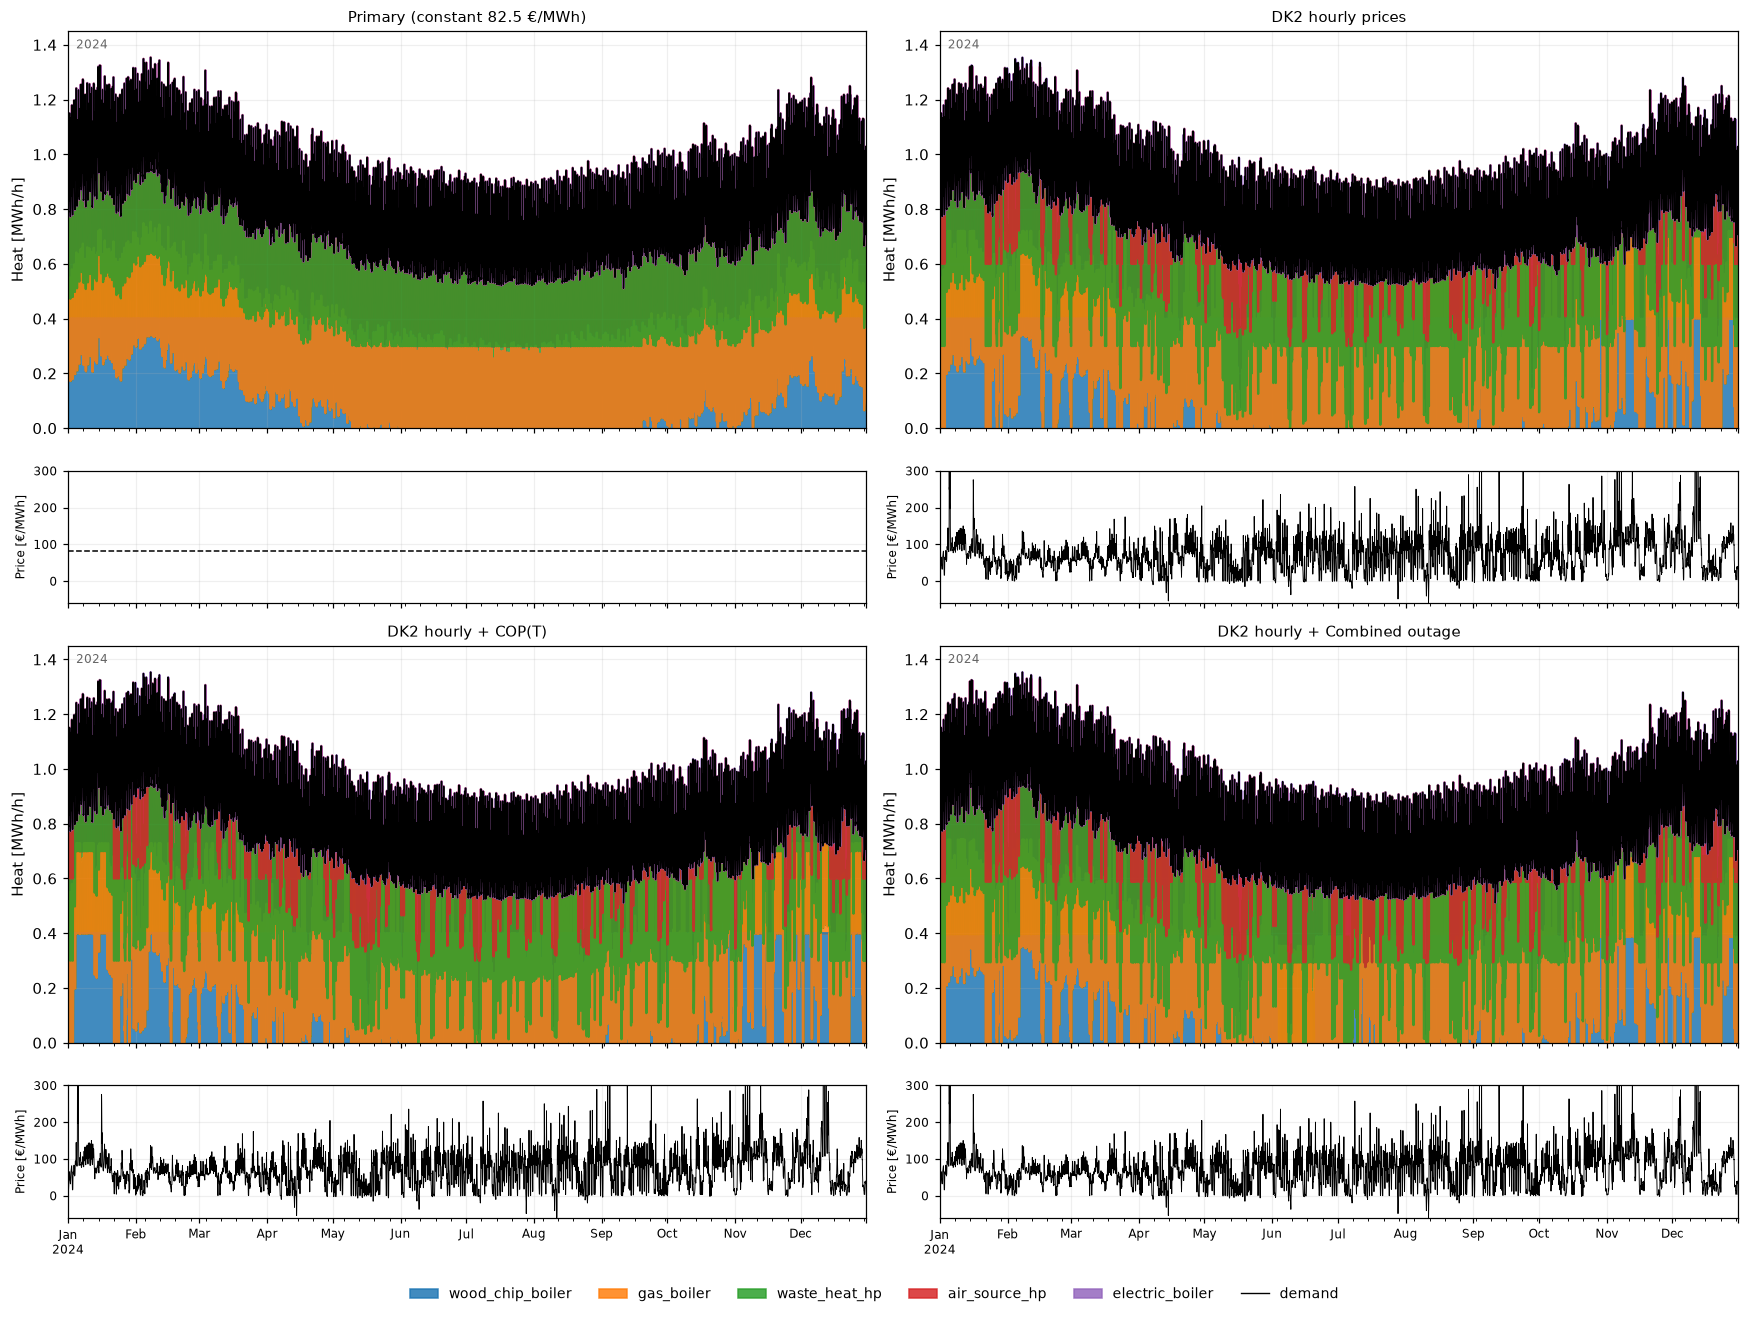

Saved: step3_dispatch_4panel_split.png


In [19]:
# ══════════════════════════════════════════════════════════════════
# Four-panel dispatch — split layout (price using pandas .plot())
# ══════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 2, figsize=(16, 12), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1, 3, 1]})

def plot_pair(ax_disp, ax_price, ho, title, prices=None):
    # ── Dispatch ───────────────────────────────────────────────
    ho[units].plot.area(ax=ax_disp, stacked=True, alpha=0.85, legend=False)
    ho["demand"].plot(ax=ax_disp, color="black", linewidth=0.9)
    ax_disp.set_ylabel("Heat [MWh/h]")
    ax_disp.set_ylim(0, 1.45)
    ax_disp.set_title(title, fontsize=10)
    ax_disp.grid(alpha=0.2)

    # ── Price ──────────────────────────────────────────────────
    if prices is not None:
        # Use pandas .plot() — handles DatetimeIndex and shared axes correctly
        prices.plot(ax=ax_price, color="black", linewidth=0.6)
    else:
        ax_price.axhline(82.5, color="black", linestyle="--", linewidth=1.0)

    ax_price.set_ylim(-60, 300)
    ax_price.set_ylabel("Price [€/MWh]", fontsize=8)
    ax_price.grid(alpha=0.2)
    ax_price.tick_params(labelsize=8)

plot_pair(axes[0, 0], axes[1, 0], heat_out,    "Primary (constant 82.5 €/MWh)")
plot_pair(axes[0, 1], axes[1, 1], heat_out_h,  "DK2 hourly prices",              prices_h)
plot_pair(axes[2, 0], axes[3, 0], heat_out_B,  "DK2 hourly + COP(T)",            prices_h)
plot_pair(axes[2, 1], axes[3, 1], heat_out_Ch, "DK2 hourly + Combined outage",   prices_h)

# Hide x-tick labels on the dispatch rows
for row in [0, 2]:
    for col in [0, 1]:
        axes[row, col].tick_params(labelbottom=False)
        axes[row, col].text(0.01, 0.98, "2024",
                            transform=axes[row, col].transAxes,
                            ha="left", va="top", fontsize=8,
                            color="#333333", alpha=0.75)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6,
           fontsize=9, frameon=False, bbox_to_anchor=(0.5, 0.0))

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(os.path.join(OUTPUT_DIR, "step3_dispatch_4panel_split.png"),
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: step3_dispatch_4panel_split.png")

STEP 3 — FIVE-SCENARIO COMPARISON

Dispatch shares [%]:
                  Primary    DK2  DK2+COP(T)  DK2+outage  DK2+min-load
wood chip boiler    22.43  26.88       26.44       26.57         27.20
gas boiler           1.17   3.20        3.65        3.99          3.12
waste heat hp       38.47  35.18       32.11       34.11         34.89
air source hp       37.93  29.62       32.69       29.25         29.09
electric boiler      0.00   5.11        5.11        6.08          5.70

Cost metrics:
                Primary        DK2  DK2+COP(T)  DK2+outage  DK2+min-load
LCOH [€/MWh]      37.67      33.31       33.25       33.70         33.43
OPEX [€/yr]   227274.44  195265.36   194758.91   197904.86     195864.79

Installed capacities [MW]:
                  Primary     DK2  DK2+COP(T)  DK2+outage  DK2+min-load
wood chip boiler   0.4000  0.4000      0.4000      0.3880        0.4000
gas boiler         0.3542  0.3205      0.3289      0.3543        0.2920
waste heat hp      0.3000  0.3000      0

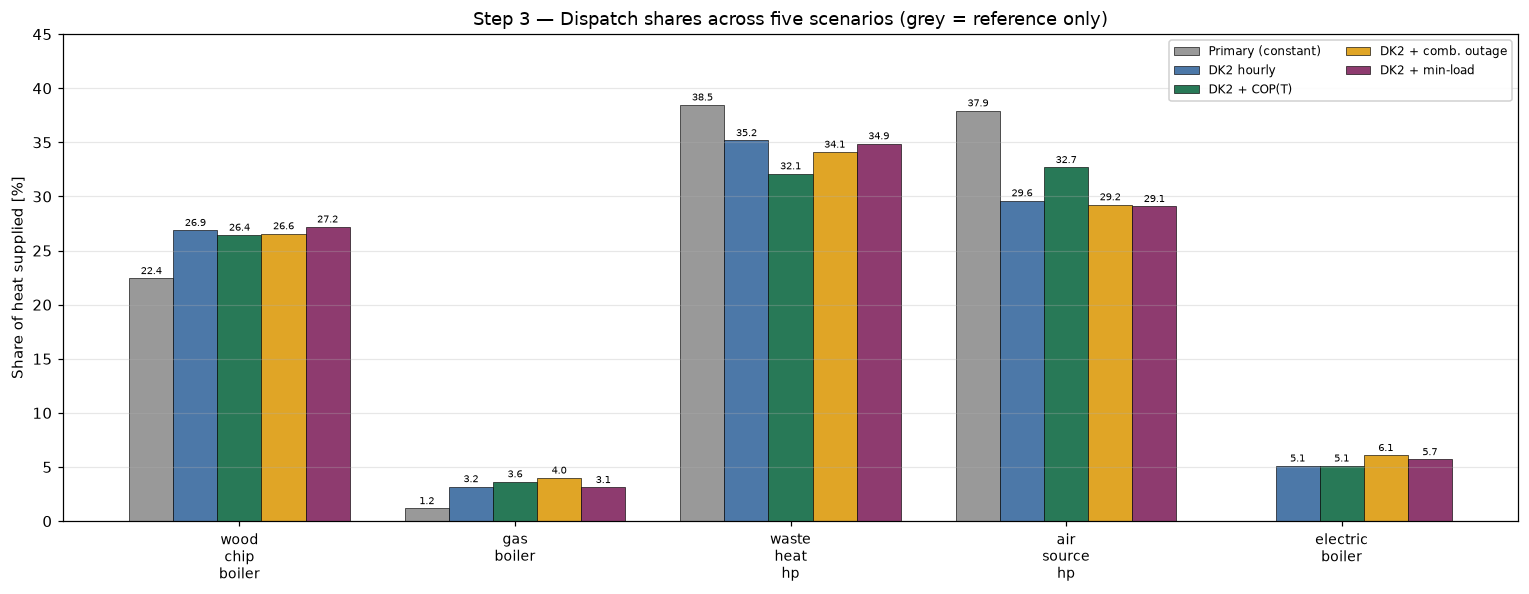

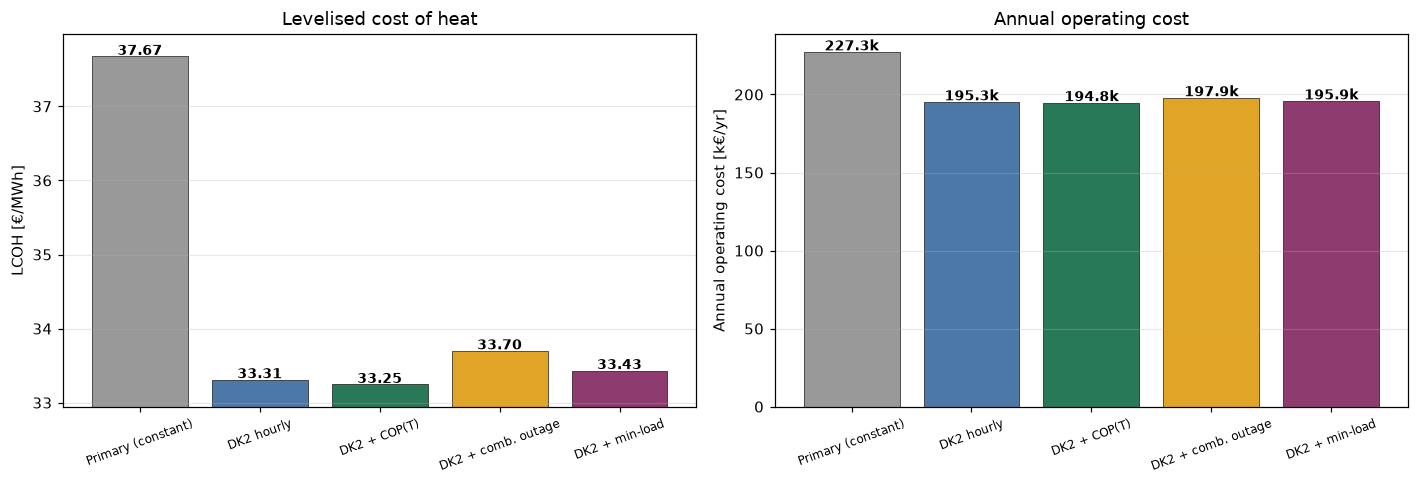

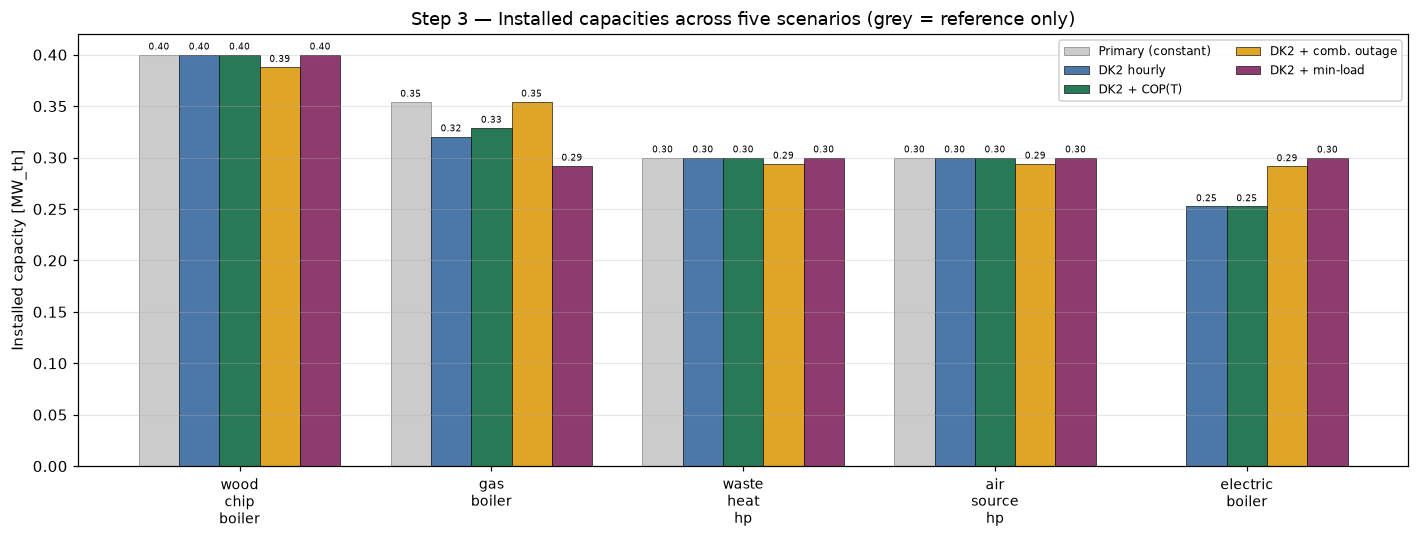


HEADLINE FINDINGS (DK2-hourly scenarios only)
  LCOH range: 33.25 – 33.70 €/MWh  (spread 0.45 = 1.4 %)
  OPEX range: 194,759 – 197,905 €/yr  (spread 1.6 %)


In [20]:
# ══════════════════════════════════════════════════════════════════
# STEP 3 — Five-scenario comparison
# Primary (reference) + four DK2-hourly operational scenarios
# ══════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

scenario_keys = ["share", "share_h", "share_B", "share_Ch", "share_nl"]
scenario_labels = [
    "Primary\n(constant)",
    "DK2\nhourly",
    "DK2 +\nCOP(T)",
    "DK2 +\ncomb. outage",
    "DK2 +\nmin-load",
]
scenario_short = ["Primary", "DK2", "DK2+COP(T)", "DK2+outage", "DK2+min-load"]

# ── Dispatch shares table ──────────────────────────────────────
shares_data = {}
for key, label in zip(scenario_keys, scenario_short):
    s = globals()[key]
    # Normalise: if values are < 1.5, multiply by 100
    vals = s.values if hasattr(s, "values") else s
    if vals.max() < 1.5:
        vals = vals * 100
    shares_data[label] = np.round(vals, 2)

shares_tbl = pd.DataFrame(shares_data,
    index=[u.replace("_", " ") for u in units])

print("="*90)
print("STEP 3 — FIVE-SCENARIO COMPARISON")
print("="*90)
print("\nDispatch shares [%]:")
print(shares_tbl.to_string())

# ── Cost metrics ───────────────────────────────────────────────
cost_keys = [("Primary",    lcoh,   op_cost),
             ("DK2",        lcoh_h, op_h),
             ("DK2+COP(T)", lcoh_B, op_B),
             ("DK2+outage", lcoh_Ch,op_Ch),
             ("DK2+min-load",lcoh_nl,op_nl)]

costs_tbl = pd.DataFrame({
    label: [lc, op] for label, lc, op in cost_keys
}, index=["LCOH [€/MWh]", "OPEX [€/yr]"])

print("\nCost metrics:")
print(costs_tbl.round(2).to_string())

# ── Installed capacities ───────────────────────────────────────
caps_data = {
    "Primary":         [capacities[u] for u in units],
    "DK2":             [caps_h[u]     for u in units],
    "DK2+COP(T)":      [caps_B[u]     for u in units],
    "DK2+outage":      [caps_Ch[u]    for u in units],
    "DK2+min-load":    [caps_nl[u]    for u in units],
}
caps_tbl = pd.DataFrame(caps_data,
    index=[u.replace("_", " ") for u in units])

print("\nInstalled capacities [MW]:")
print(caps_tbl.round(4).to_string())

# ── Save ───────────────────────────────────────────────────────
shares_tbl.to_csv(OUTPUT_DIR / "step3_five_scenario_shares.csv")
costs_tbl.to_csv(OUTPUT_DIR / "step3_five_scenario_costs.csv")
caps_tbl.to_csv(OUTPUT_DIR / "step3_five_scenario_capacities.csv")
print("\nSaved: step3_five_scenario_shares.csv, _costs.csv, _capacities.csv")

# ── Figure 1: shares across five scenarios ─────────────────────
x = np.arange(len(units))
w = 0.16
colors = ["#999999", "#4c78a8", "#287957", "#e0a526", "#8e3b6f"]

fig, ax = plt.subplots(figsize=(14, 5.5))
for i, (label, color) in enumerate(zip(scenario_labels, colors)):
    offset = (i - 2) * w
    bars = ax.bar(x + offset, shares_tbl.iloc[:, i].values, w,
                  label=label.replace("\n", " "),
                  color=color, edgecolor="black", linewidth=0.4)
    for bar in bars:
        h = bar.get_height()
        if h > 0.1:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.4,
                    f"{h:.1f}", ha="center", fontsize=6.5)

ax.set_xticks(x)
ax.set_xticklabels([u.replace("_", "\n") for u in units], fontsize=9)
ax.set_ylabel("Share of heat supplied [%]")
ax.set_title("Step 3 — Dispatch shares across five scenarios "
             "(grey = reference only)")
ax.legend(loc="upper right", fontsize=8, framealpha=0.9, ncol=2)
ax.grid(axis="y", alpha=0.3)
ax.set_ylim(0, 45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step3_five_scenario_shares.png", dpi=150)
plt.show()

# ── Figure 2: LCOH and OPEX across five scenarios ──────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

lcoh_vals = [v[0] for v in [c[1:] for c in cost_keys]]
opex_vals = [v[1] for v in [c[1:] for c in cost_keys]]
scen = [l.replace("\n", " ") for l in scenario_labels]

ax = axes[0]
bars = ax.bar(scen, lcoh_vals, color=colors,
              edgecolor="black", linewidth=0.4)
for bar, v in zip(bars, lcoh_vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.02,
            f"{v:.2f}", ha="center", fontsize=9, weight="bold")
ax.set_ylabel("LCOH [€/MWh]")
ax.set_title("Levelised cost of heat")
ax.set_ylim(min(lcoh_vals) - 0.3, max(lcoh_vals) + 0.3)
ax.tick_params(axis="x", rotation=20, labelsize=8)
ax.grid(axis="y", alpha=0.3)

ax = axes[1]
bars = ax.bar(scen, [v/1000 for v in opex_vals], color=colors,
              edgecolor="black", linewidth=0.4)
for bar, v in zip(bars, opex_vals):
    ax.text(bar.get_x() + bar.get_width()/2, v/1000 + 1,
            f"{v/1000:.1f}k", ha="center", fontsize=9, weight="bold")
ax.set_ylabel("Annual operating cost [k€/yr]")
ax.set_title("Annual operating cost")
ax.tick_params(axis="x", rotation=20, labelsize=8)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step3_five_scenario_costs.png", dpi=150)
plt.show()

# ── Figure 3: installed capacities ─────────────────────────────
fig, ax = plt.subplots(figsize=(13, 5))
for i, (label, color) in enumerate(zip(scenario_labels, colors)):
    offset = (i - 2) * w
    bars = ax.bar(x + offset, caps_tbl.iloc[:, i].values, w,
                  label=label.replace("\n", " "),
                  color=color, edgecolor="black", linewidth=0.4,
                  alpha=0.5 if i == 0 else 1.0)   # fade the reference
    for bar in bars:
        h = bar.get_height()
        if h > 0.01:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.005,
                    f"{h:.2f}", ha="center", fontsize=6)

ax.set_xticks(x)
ax.set_xticklabels([u.replace("_", "\n") for u in units], fontsize=9)
ax.set_ylabel("Installed capacity [MW_th]")
ax.set_title("Step 3 — Installed capacities across five scenarios "
             "(grey = reference only)")
ax.legend(loc="upper right", fontsize=8, framealpha=0.9, ncol=2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step3_five_scenario_capacities.png", dpi=150)
plt.show()

# ── Insights table for the report ──────────────────────────────
print("\n" + "="*90)
print("HEADLINE FINDINGS (DK2-hourly scenarios only)")
print("="*90)

dk2_only = ["DK2", "DK2+COP(T)", "DK2+outage", "DK2+min-load"]
dk2_lcoh = [lc for lbl, lc, op in cost_keys if lbl in dk2_only]
dk2_opex = [op for lbl, lc, op in cost_keys if lbl in dk2_only]
print(f"  LCOH range: {min(dk2_lcoh):.2f} – {max(dk2_lcoh):.2f} €/MWh  "
      f"(spread {max(dk2_lcoh)-min(dk2_lcoh):.2f} = "
      f"{(max(dk2_lcoh)-min(dk2_lcoh))/min(dk2_lcoh)*100:.1f} %)")
print(f"  OPEX range: {min(dk2_opex):,.0f} – {max(dk2_opex):,.0f} €/yr  "
      f"(spread {(max(dk2_opex)-min(dk2_opex))/min(dk2_opex)*100:.1f} %)")

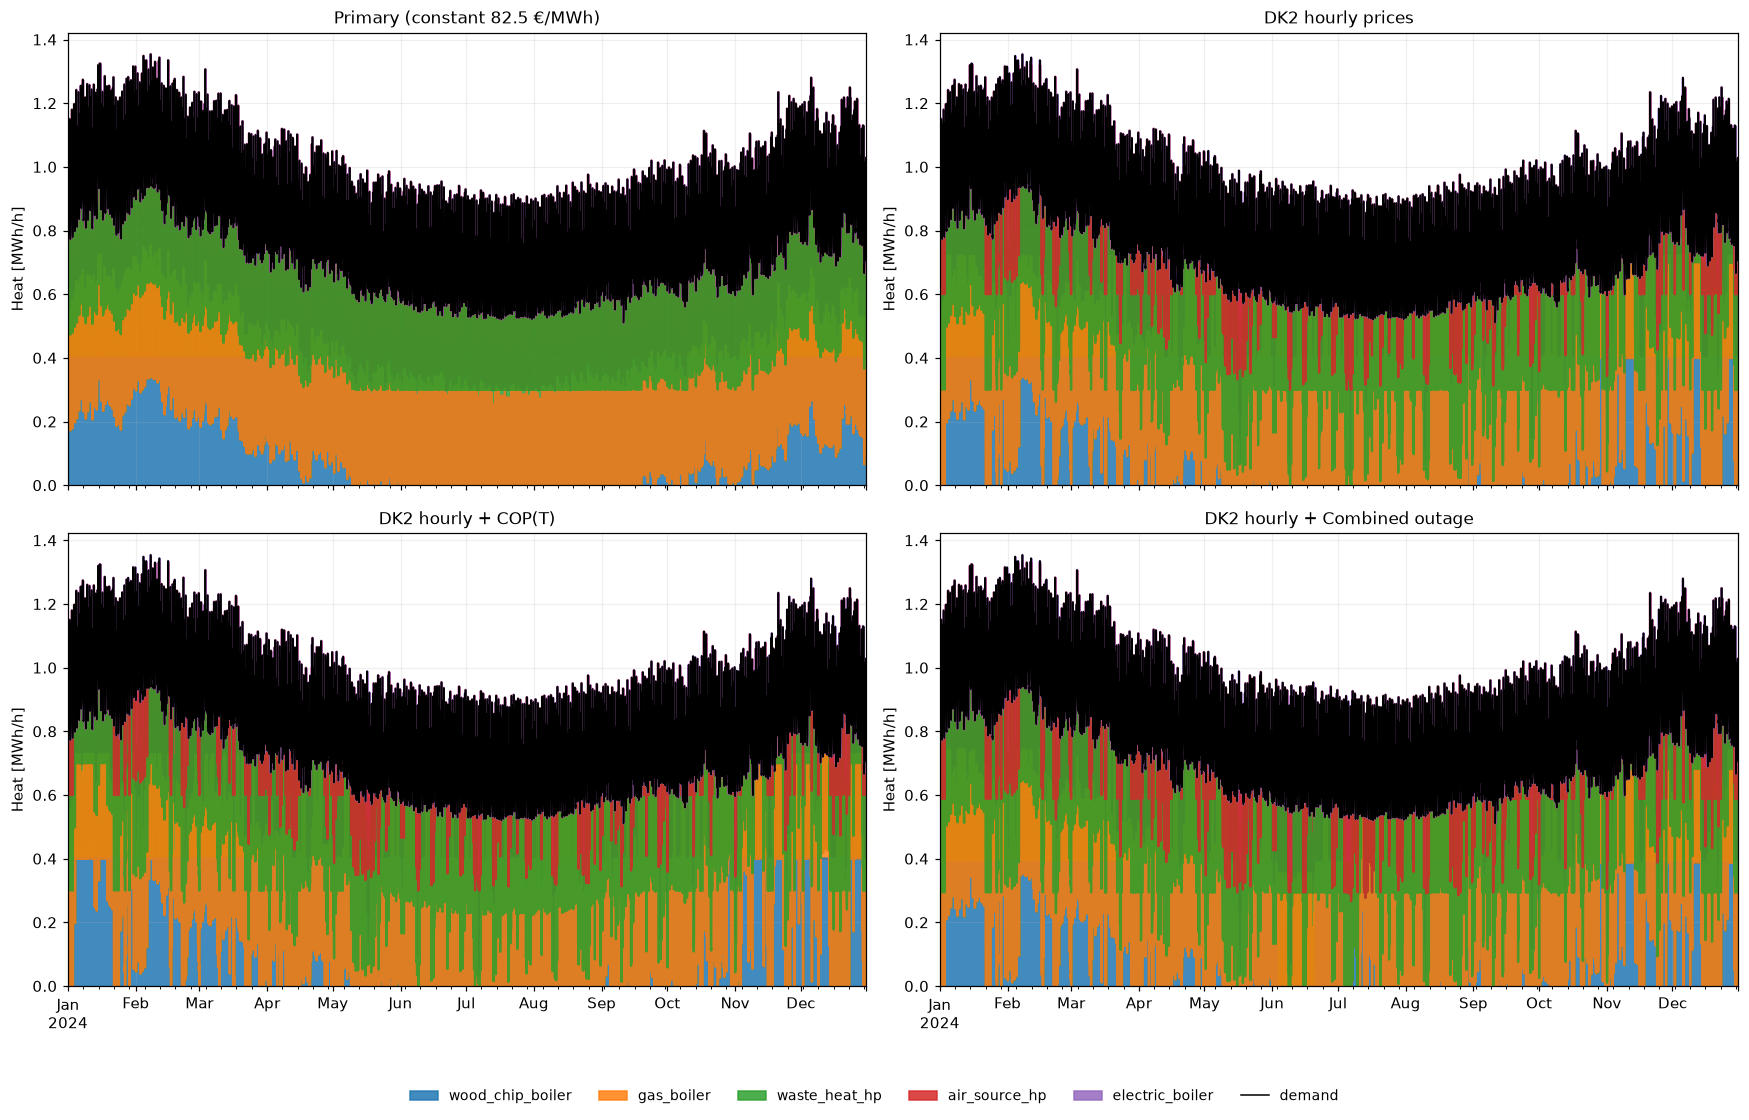

heat_out        defined? ✓
heat_out_h      defined? ✓
heat_out_B      defined? ✓
heat_out_Ch     defined? ✓
heat_out_nl     defined? ✓
Saved: C:\Users\Jeffery\Desktop\Opt proj 2\Step3_results/step3_dispatch_DK2.csv, C:\Users\Jeffery\Desktop\Opt proj 2\Step3_results/step3_aggregated_demand_DK2.csv
Step 3 annual balance (DK2) ✓


In [21]:

# ══════════════════════════════════════════════════════════════════
# Four-panel dispatch comparison
# ══════════════════════════════════════════════════════════════════
scenarios = [
    ("Primary (constant 82.5 €/MWh)",       heat_out,   None),
    ("DK2 hourly prices",                    heat_out_h, None),
    ("DK2 hourly + COP(T)",                  heat_out_B, None),
    ("DK2 hourly + Combined outage",         heat_out_Ch,None),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
axes = axes.flatten()

for ax, (title, ho, _) in zip(axes, scenarios):
    ho[units].plot.area(ax=ax, stacked=True, alpha=0.85, legend=False)
    ho["demand"].plot(ax=ax, color="black", linewidth=1.0)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("Heat [MWh/h]")
    ax.set_xlabel("")
    ax.grid(alpha=0.2)

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6,
           fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(os.path.join(OUTPUT_DIR, "step3_dispatch_4panel.png"),
            dpi=150, bbox_inches="tight")
plt.show()

# ══════════════════════════════════════════════════════════════════
# Print 
# ══════════════════════════════════════════════════════════════════

for name in ["heat_out", "heat_out_h", "heat_out_B", "heat_out_Ch", "heat_out_nl"]:
    print(f"{name:14s}  defined? {'✓' if name in dir() else '✗'}")

heat_out_h.to_csv(os.path.join(OUTPUT_DIR, "step3_dispatch_DK2.csv"))
df_h[["heat_demand"]].to_csv(os.path.join(OUTPUT_DIR, "step3_aggregated_demand_DK2.csv"))
print(f"Saved: {OUTPUT_DIR}/step3_dispatch_DK2.csv, "
      f"{OUTPUT_DIR}/step3_aggregated_demand_DK2.csv")

assert abs(heat_out_h[units].sum().sum() - df_h["heat_demand"].sum()) < 1e-3
print("Step 3 annual balance (DK2) ✓")

In [22]:
# ══════════════════════════════════════════════════════════════════
# Step 4 — Integration of DHNx distribution losses with oemof.solph
# ══════════════════════════════════════════════════════════════════
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import oemof.solph as solph
from oemof.solph import processing

OUTPUT_DIR_S4 = PROJECT_DIR / "Step4_results"
OUTPUT_DIR_S4.mkdir(parents=True, exist_ok=True)

# ── 1. Read DHNx distribution losses from Step 2 (Q_losses) ─────────────────
# Automatically find summary.json in the Step 2 results folder, or enter manually if not found.
step2_Summaries = list(PROJECT_DIR.glob("**/Step2*_results/run_*/summary.json"))

if step2_Summaries:
    latest_summary = max(step2_Summaries, key=lambda p: p.stat().st_mtime)
    s2_data = json.loads(latest_summary.read_text(encoding="utf-8"))
    loss_kW = float(s2_data["network_loss_kW"])
    print(f"Successfully read Step 2 heat losses from {latest_summary.parent.name}:")
else:
    # ⚠️ If the Step 2 result file is not found, manually replace None with the calculated network_loss_kW value from Step 2.
    loss_kW = None 
    if loss_kW is None:
        raise FileNotFoundError(
            "Step 2 summary.json not found! Please provide the file or manually set loss_kW = your_value (kW) above."
        )

loss_MW = loss_kW / 1000.0  # Unit conversion: kW -> MW (matching the MWh/h unit from Step 3)
annual_loss_MWh = loss_MW * 8760

print(f"  Constant hourly heat loss (Q_losses): {loss_kW:.4f} kW ({loss_MW:.6f} MW)")
print(f"  Total annual network heat loss:       {annual_loss_MWh:.2f} MWh")

# ── 2. Create the adjusted total load profile (Q_totdl = Q_demand + Q_losses)
df_s4_const = df.copy()
df_s4_const["consumer_demand_MW"] = df["heat_demand"]
df_s4_const["network_loss_MW"]    = loss_MW
df_s4_const["heat_demand"]        = df["heat_demand"] + loss_MW  # Replace with total load

df_s4_dk2 = df_h.copy()
df_s4_dk2["consumer_demand_MW"] = df_h["heat_demand"]
df_s4_dk2["network_loss_MW"]    = loss_MW
df_s4_dk2["heat_demand"]        = df_h["heat_demand"] + loss_MW

df_s4_const.to_csv(OUTPUT_DIR_S4 / "step4_adjusted_demand_input.csv")

print(f"\nAdjusted load statistics (Q_totdl):")
print(f"  Step 3 original annual demand: {df['heat_demand'].sum():,.2f} MWh | Peak: {df['heat_demand'].max():.4f} MW")
print(f"  Step 4 adjusted annual total load: {df_s4_const['heat_demand'].sum():,.2f} MWh | Peak: {df_s4_const['heat_demand'].max():.4f} MW")
print(f"  Maximum total system installed capacity: {(P1_CAP+P2_CAP+P3_CAP+P4_CAP+P5_CAP)/1000.0:.4f} MW")

# ── 3. Define common simulation and analysis functions (ensure parameters match Step 3)
def run_step4_scenario(df_input, tag, s3_dispatch, s3_caps, s3_opex, s3_lcoh):
    # Call the model builder build_es_h defined in Step 3
    es_s4, b_heat_s4 = build_es_h(df_input, tag=tag)
    model_s4 = solph.Model(es_s4)
    model_s4.solve(solver="cbc", solve_kwargs={"tee": False}, cmdline_options={"ratioGap": "0.02"})
    res_s4 = processing.results(model_s4)
    
    N = len(df_input)
    dispatch_s4 = pd.DataFrame(index=df_input.index)
    caps_s4 = {}
    
    for u in units:
        label = f"{u}{tag}"
        seq = res_s4[(es_s4.groups[label], b_heat_s4)]["sequences"]["flow"].values
        dispatch_s4[u] = seq[:N]
        caps_s4[u] = res_s4[(es_s4.groups[label], b_heat_s4)]["scalars"].get("invest", 0.0)
        
    dispatch_s4["demand"] = df_input["heat_demand"].values
    dispatch_s4["consumer_demand"] = df_input["consumer_demand_MW"].values
    dispatch_s4["network_loss"] = df_input["network_loss_MW"].values
    
    # Calculate fuel and operational costs (OPEX)
    fuel_cost_series = {
        "wood_chip_boiler": (1/ETA_WCB)  * df_input["biomass_price"],
        "gas_boiler":       (1/ETA_GB)   * df_input["gas_price"],
        "waste_heat_hp":    (1/COP_WH)   * df_input["electricity_price"],
        "air_source_hp":    (1/COP_ASHP) * df_input["electricity_price"],
        "electric_boiler":  (1/ETA_EB)   * df_input["electricity_price"],
    }
    
    opex_s4 = sum((dispatch_s4[u] * fuel_cost_series[u]).sum() + dispatch_s4[u].sum() * var_cost[u] for u in units)
    raw_capex_s4 = sum(caps_s4[u] * spec_inv[u] for u in units)
    
    total_generated_MWh = dispatch_s4[units].sum().sum()
    delivered_heat_MWh  = df_input["consumer_demand_MW"].sum()
    
    # Calculate two types of LCOH: divided by total generated heat vs divided by delivered heat
    lcoh_gen = LCOH(raw_capex_s4, opex_s4, total_generated_MWh, i=INTEREST_RATE, n=LIFE_YEARS)
    lcoh_del = LCOH(raw_capex_s4, opex_s4, delivered_heat_MWh, i=INTEREST_RATE, n=LIFE_YEARS)
    
    # Unit comparison table
    s3_gen = s3_dispatch[units].sum()
    s4_gen = dispatch_s4[units].sum()
    
    unit_cmp = pd.DataFrame({
        "S3_Cap_MW": pd.Series(s3_caps),
        "S4_Cap_MW": pd.Series(caps_s4),
        "Cap_Diff_MW": pd.Series(caps_s4) - pd.Series(s3_caps),
        "S3_Gen_MWh": s3_gen,
        "S4_Gen_MWh": s4_gen,
        "Gen_Diff_MWh": s4_gen - s3_gen,
        "S3_Share_%": s3_gen / s3_gen.sum() * 100,
        "S4_Share_%": s4_gen / s4_gen.sum() * 100,
        "Share_Diff_pp": (s4_gen / s4_gen.sum() * 100) - (s3_gen / s3_gen.sum() * 100),
        "S4_Hours_at_Max_Cap": [(dispatch_s4[u] >= caps_s4[u]*0.999).sum() if caps_s4[u]>0 else 0 for u in units]
    })
    
    sys_summary = {
        "Total_Gen_S3_MWh": s3_gen.sum(),
        "Total_Gen_S4_MWh": s4_gen.sum(),
        "OPEX_S3_EUR": s3_opex,
        "OPEX_S4_EUR": opex_s4,
        "OPEX_Diff_%": (opex_s4 - s3_opex) / s3_opex * 100,
        "LCOH_S3_EUR_MWh": s3_lcoh,
        "LCOH_S4_Generated_EUR_MWh": lcoh_gen,
        "LCOH_S4_Delivered_EUR_MWh": lcoh_del,
        "Network_Efficiency_%": delivered_heat_MWh / total_generated_MWh * 100
    }
    
    return dispatch_s4, caps_s4, unit_cmp, sys_summary

# ── 4. Execute simulations (Primary constant price & DK2 dynamic spot price) ──
print("\nExecuting simulations...")
disp_s4_pri, caps_s4_pri, cmp_pri, sys_pri = run_step4_scenario(
    df_s4_const, "_s4_pri", heat_out, capacities, op_cost, lcoh
)
disp_s4_dk2, caps_s4_dk2, cmp_dk2, sys_dk2 = run_step4_scenario(
    df_s4_dk2, "_s4_dk2", heat_out_h, caps_h, op_h, lcoh_h
)

# Save results for Step 5
disp_s4_pri.to_csv(OUTPUT_DIR_S4 / "step4_dispatch_primary.csv")
disp_s4_dk2.to_csv(OUTPUT_DIR_S4 / "step4_dispatch_DK2.csv")
cmp_pri.to_csv(OUTPUT_DIR_S4 / "step4_comparison_primary.csv")
cmp_dk2.to_csv(OUTPUT_DIR_S4 / "step4_comparison_DK2.csv")

print("\n=== [Scenario 1: Primary (Constant price 82.5 €/MWh)] Step 3 vs Step 4 Unit Comparison ===")
print(cmp_pri.round(2).to_string())
print("\nSystem Overview (Primary):", json.dumps({k: round(v, 2) for k, v in sys_pri.items()}, indent=2))

print("\n=== [Scenario 2: DK2 (2024 Dynamic Spot Price)] Step 3 vs Step 4 Unit Comparison ===")
print(cmp_dk2.round(2).to_string())
print("\nSystem Overview (DK2):", json.dumps({k: round(v, 2) for k, v in sys_dk2.items()}, indent=2))

Successfully read Step 2 heat losses from run_20261012_105559_350059:
  Constant hourly heat loss (Q_losses): 8.7497 kW (0.008750 MW)
  Total annual network heat loss:       76.65 MWh

Adjusted load statistics (Q_totdl):
  Step 3 original annual demand: 6,831.13 MWh | Peak: 1.3542 MW
  Step 4 adjusted annual total load: 6,907.78 MWh | Peak: 1.3629 MW
  Maximum total system installed capacity: 1.7000 MW

Executing simulations...


c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:182: FutureWarning: For backward compatibility, the option nominal_value overwrites the option nominal_capacity. Both options cannot be set at the same time.
  warn(msg, FutureWarning)
INFO:root:Optimization successful.
c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:182: FutureWarning: For backward compatibility, the option nominal_value overwrites the option nominal_capacity. Both options cannot be set at the same time.
  warn(msg, FutureWarning)
INFO:root:Optimization successful.



=== [Scenario 1: Primary (Constant price 82.5 €/MWh)] Step 3 vs Step 4 Unit Comparison ===
                  S3_Cap_MW  S4_Cap_MW  Cap_Diff_MW  S3_Gen_MWh  S4_Gen_MWh  Gen_Diff_MWh  S3_Share_%  S4_Share_%  Share_Diff_pp  S4_Hours_at_Max_Cap
wood_chip_boiler       0.40       0.40         0.00     1531.94     1591.84         59.90       22.43       23.04           0.62                  897
gas_boiler             0.35       0.36         0.01       80.07       87.60          7.53        1.17        1.27           0.10                    1
waste_heat_hp          0.30       0.30         0.00     2628.00     2628.00          0.00       38.47       38.04          -0.43                 8760
air_source_hp          0.30       0.30         0.00     2591.12     2600.34          9.22       37.93       37.64          -0.29                 7813
electric_boiler        0.00       0.00         0.00        0.00        0.00          0.00        0.00        0.00           0.00                    0

System 

In [23]:
# ══════════════════════════════════════════════════════════════════
# Step 5 — Environmental Optimization (Adding CO2 Emission Costs)
# ══════════════════════════════════════════════════════════════════
import json
import pandas as pd
import numpy as np
import oemof.solph as solph
from oemof.solph import processing, EnergySystem, Bus, Flow, Investment
from oemof.solph.components import Source, Sink, Converter

OUTPUT_DIR_S5 = PROJECT_DIR / "Step5_results"
OUTPUT_DIR_S5.mkdir(parents=True, exist_ok=True)

# ── 1. Environmental Parameters ───────────────────────────────────────────
CO2_PRC = 90.0  # Carbon Price (€/ton)

# Emission Factors (ton/MWh)
EF_WOOD = 0.000 
EF_GAS  = 0.202 
EF_ELEC = 0.082 

print(f"Carbon Price: {CO2_PRC} EUR/ton")
print(f"Emission Factors (t/MWh) -> Wood: {EF_WOOD}, Gas: {EF_GAS}, Elec: {EF_ELEC}")

# ── 2. Step 5 Model Builder (Scenario A & B) ──────────────────────────────
def build_es_s5(df_in, tag, scenario="A"):
    es = EnergySystem(timeindex=df_in.index, infer_last_interval=True)
    
    b_heat = Bus(label=f"heat_bus{tag}")
    b_elec = Bus(label=f"elec_bus{tag}")
    b_bio  = Bus(label=f"biomass_bus{tag}")
    b_gas  = Bus(label=f"gas_bus{tag}")
    b_wst  = Bus(label=f"waste_heat_bus{tag}")
    
    es.add(b_heat, b_elec, b_bio, b_gas, b_wst)
    
    if scenario == "A":
        c_bio  = df_in["biomass_price"]     + (EF_WOOD * CO2_PRC)
        c_gas  = df_in["gas_price"]         + (EF_GAS  * CO2_PRC)
        c_elec = df_in["electricity_price"] + (EF_ELEC * CO2_PRC)
        v_wcb, v_gb, v_wh, v_ashp, v_eb = VOM_WCB, VOM_GB, VOM_WH, VOM_ASHP, VOM_EB
    elif scenario == "B":
        c_bio  = pd.Series(EF_WOOD * CO2_PRC, index=df_in.index)
        c_gas  = pd.Series(EF_GAS  * CO2_PRC, index=df_in.index)
        c_elec = pd.Series(EF_ELEC * CO2_PRC, index=df_in.index)
        v_wcb = v_gb = v_wh = v_ashp = v_eb = 0.0
    else:
        raise ValueError("Scenario must be 'A' or 'B'.")

    es.add(Source(label=f"electricity_grid{tag}", outputs={b_elec: Flow(variable_costs=c_elec)}))
    es.add(Source(label=f"biomass_fuel{tag}", outputs={b_bio: Flow(variable_costs=c_bio)}))
    es.add(Source(label=f"gas_fuel{tag}", outputs={b_gas: Flow(variable_costs=c_gas)}))
    es.add(Source(label=f"waste_heat_source{tag}", outputs={b_wst: Flow(variable_costs=0.0)}))
    
    es.add(Sink(label=f"heat_demand{tag}",
        inputs={b_heat: Flow(
            nominal_value=df_in["heat_demand"].max(),
            fix=(df_in["heat_demand"] / df_in["heat_demand"].max()).values)}))
            
    es.add(Converter(label=f"wood_chip_boiler{tag}",
        inputs={b_bio: Flow()},
        outputs={b_heat: Flow(nominal_value=Investment(ep_costs=epc_30(CAPEX_WCB), maximum=MAX_WCB), variable_costs=v_wcb)},
        conversion_factors={b_bio: ETA_WCB}))
        
    es.add(Converter(label=f"gas_boiler{tag}",
        inputs={b_gas: Flow()},
        outputs={b_heat: Flow(nominal_value=Investment(ep_costs=epc_30(CAPEX_GB), maximum=MAX_GB), variable_costs=v_gb)},
        conversion_factors={b_gas: ETA_GB}))
        
    es.add(Converter(label=f"waste_heat_hp{tag}",
        inputs={b_wst: Flow(), b_elec: Flow()},
        outputs={b_heat: Flow(nominal_value=Investment(ep_costs=epc_30(CAPEX_WH), maximum=MAX_WH), variable_costs=v_wh)},
        conversion_factors={b_wst: (COP_WH-1)/COP_WH, b_elec: 1/COP_WH}))
        
    es.add(Converter(label=f"air_source_hp{tag}",
        inputs={b_elec: Flow()},
        outputs={b_heat: Flow(nominal_value=Investment(ep_costs=epc_30(CAPEX_ASHP), maximum=MAX_ASHP), variable_costs=v_ashp)},
        conversion_factors={b_elec: 1/COP_ASHP}))
        
    es.add(Converter(label=f"electric_boiler{tag}",
        inputs={b_elec: Flow()},
        outputs={b_heat: Flow(nominal_value=Investment(ep_costs=epc_30(CAPEX_EB), maximum=MAX_EB), variable_costs=v_eb)},
        conversion_factors={b_elec: ETA_EB}))
        
    return es, b_heat

# ── 3. Execution and Analysis Function ────────────────────────────────────────
def run_step5_scenario(df_input, scenario, tag):
    es_s5, b_heat_s5 = build_es_s5(df_input, tag, scenario=scenario)
    model_s5 = solph.Model(es_s5)
    model_s5.solve(solver="cbc", solve_kwargs={"tee": False}, cmdline_options={"ratioGap": "0.02"})
    res_s5 = processing.results(model_s5)
    
    N = len(df_input)
    dispatch_s5 = pd.DataFrame(index=df_input.index)
    
    for u in units:
        label = f"{u}{tag}"
        seq = res_s5[(es_s5.groups[label], b_heat_s5)]["sequences"]["flow"].values
        dispatch_s5[u] = seq[:N]
    
    emissions = pd.Series(0.0, index=units)
    emissions["wood_chip_boiler"] = (dispatch_s5["wood_chip_boiler"].sum() / ETA_WCB) * EF_WOOD
    emissions["gas_boiler"]       = (dispatch_s5["gas_boiler"].sum() / ETA_GB) * EF_GAS
    emissions["waste_heat_hp"]    = (dispatch_s5["waste_heat_hp"].sum() / COP_WH) * EF_ELEC
    emissions["air_source_hp"]    = (dispatch_s5["air_source_hp"].sum() / COP_ASHP) * EF_ELEC
    emissions["electric_boiler"]  = (dispatch_s5["electric_boiler"].sum() / ETA_EB) * EF_ELEC
    
    total_emissions = emissions.sum()
    gen_s5 = dispatch_s5[units].sum()
    shares_s5 = gen_s5 / gen_s5.sum() * 100
    
    return dispatch_s5, shares_s5, total_emissions

# ── 4. Run Step 5 Scenarios ───────────────────────────────────────────────────
print("\nExecuting Step 5 Scenarios...")
disp_s5A, shares_s5A, em_s5A = run_step5_scenario(df_s4_dk2, scenario="A", tag="_s5A")
disp_s5B, shares_s5B, em_s5B = run_step5_scenario(df_s4_dk2, scenario="B", tag="_s5B")

disp_s5A.to_csv(OUTPUT_DIR_S5 / "step5_scenarioA_dispatch.csv")
disp_s5B.to_csv(OUTPUT_DIR_S5 / "step5_scenarioB_dispatch.csv")

# ── 5. Comparison Output ────────────────────────────────────────────────────
try:
    s4_shares = cmp_dk2["S4_Share_%"]
except NameError:
    s4_shares = pd.Series(0, index=units)

cmp_s5 = pd.DataFrame({
    "Step 4 (No CO2 Cost) %": s4_shares,
    "Step 5A (Cost+CO2) %": shares_s5A,
    "Step 5B (Only CO2) %": shares_s5B
})

print("\n=== Generation Mix Comparison (%) ===")
print(cmp_s5.round(2).to_string())

print("\n=== Total CO2 Emissions (Tons per year) ===")
print(f"  Step 5A (Economic + Environmental): {em_s5A:,.2f} Tons")
print(f"  Step 5B (Strictly Environmental):   {em_s5B:,.2f} Tons")
print(f"  Emission Reduction in Scenario B:   {(em_s5A - em_s5B):,.2f} Tons")

Carbon Price: 90.0 EUR/ton
Emission Factors (t/MWh) -> Wood: 0.0, Gas: 0.202, Elec: 0.082

Executing Step 5 Scenarios...


c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:182: FutureWarning: For backward compatibility, the option nominal_value overwrites the option nominal_capacity. Both options cannot be set at the same time.
  warn(msg, FutureWarning)
INFO:root:Optimization successful.
c:\Users\Jeffery\anaconda3\envs\dhnx_env\Lib\site-packages\oemof\solph\flows\_flow.py:182: FutureWarning: For backward compatibility, the option nominal_value overwrites the option nominal_capacity. Both options cannot be set at the same time.
  warn(msg, FutureWarning)
INFO:root:Optimization successful.



=== Generation Mix Comparison (%) ===
                  Step 4 (No CO2 Cost) %  Step 5A (Cost+CO2) %  Step 5B (Only CO2) %
wood_chip_boiler                   27.02                 30.61                 50.73
gas_boiler                          3.32                  1.45                  0.99
waste_heat_hp                      34.92                 36.49                 34.74
air_source_hp                      29.45                 28.12                  1.92
electric_boiler                     5.29                  3.32                 11.63

=== Total CO2 Emissions (Tons per year) ===
  Step 5A (Economic + Environmental): 165.42 Tons
  Step 5B (Strictly Environmental):   148.76 Tons
  Emission Reduction in Scenario B:   16.66 Tons


In [24]:
# ── 補充：Step 5 成本計算 (OPEX 與 CO2 成本) ──
def calc_s5_costs(dispatch, df_in):
    fuel_cost_series = {
        "wood_chip_boiler": (1/ETA_WCB)  * df_in["biomass_price"],
        "gas_boiler":       (1/ETA_GB)   * df_in["gas_price"],
        "waste_heat_hp":    (1/COP_WH)   * df_in["electricity_price"],
        "air_source_hp":    (1/COP_ASHP) * df_in["electricity_price"],
        "electric_boiler":  (1/ETA_EB)   * df_in["electricity_price"],
    }
    co2_cost_series = {
        "wood_chip_boiler": (1/ETA_WCB)  * EF_WOOD * CO2_PRC,
        "gas_boiler":       (1/ETA_GB)   * EF_GAS * CO2_PRC,
        "waste_heat_hp":    (1/COP_WH)   * EF_ELEC * CO2_PRC,
        "air_source_hp":    (1/COP_ASHP) * EF_ELEC * CO2_PRC,
        "electric_boiler":  (1/ETA_EB)   * EF_ELEC * CO2_PRC,
    }
    
    # 營運成本 (燃料 + 變動維護成本)
    opex_economic = sum((dispatch[u] * fuel_cost_series[u]).sum() + dispatch[u].sum() * var_cost[u] for u in units)
    # 碳排放成本
    co2_cost = sum((dispatch[u] * co2_cost_series[u]).sum() for u in units)
    return opex_economic, co2_cost

opex_A, co2_cost_A = calc_s5_costs(disp_s5A, df_s4_dk2)
opex_B, co2_cost_B = calc_s5_costs(disp_s5B, df_s4_dk2)

print("=== Step 5 Cost Summary (EUR/yr) ===")
print(f"Scenario A (Cost + CO2): OPEX = {opex_A:,.2f} | CO2 Cost = {co2_cost_A:,.2f} | Total = {opex_A + co2_cost_A:,.2f}")
print(f"Scenario B (Only CO2)  : OPEX = {opex_B:,.2f} | CO2 Cost = {co2_cost_B:,.2f} | Total = {opex_B + co2_cost_B:,.2f}")

=== Step 5 Cost Summary (EUR/yr) ===
Scenario A (Cost + CO2): OPEX = 201,803.65 | CO2 Cost = 14,887.74 | Total = 216,691.39
Scenario B (Only CO2)  : OPEX = 279,904.52 | CO2 Cost = 13,388.56 | Total = 293,293.08


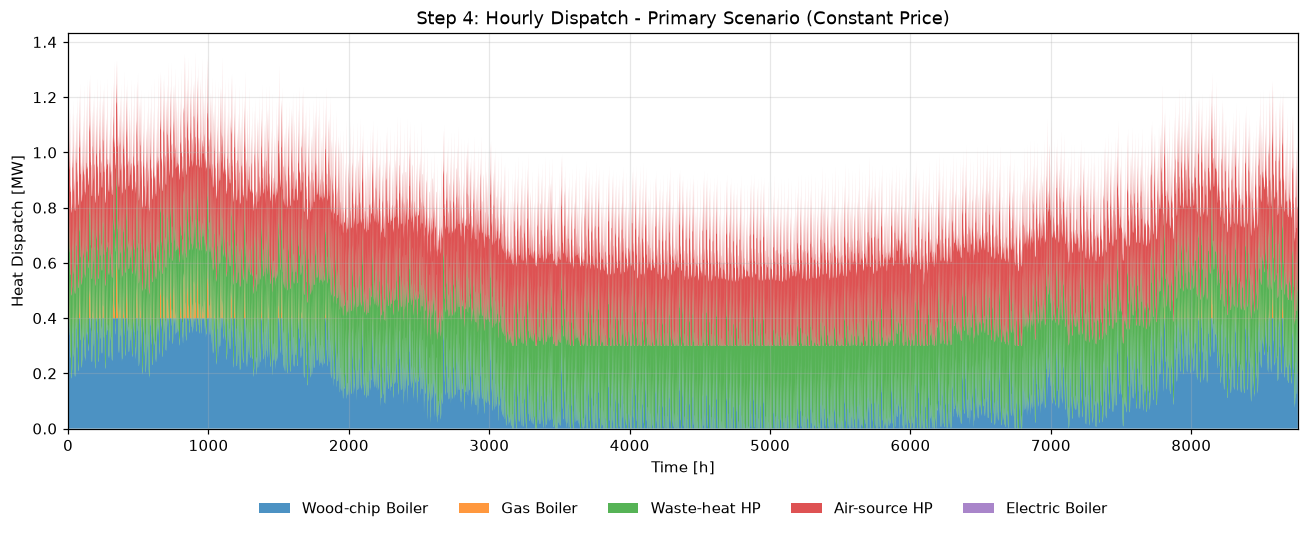

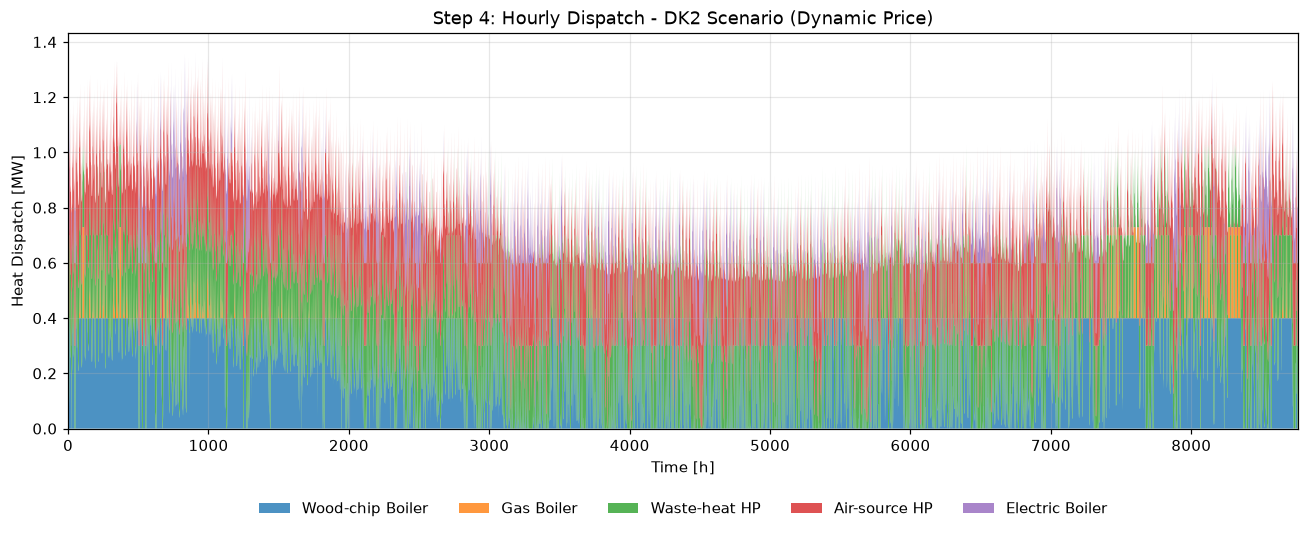

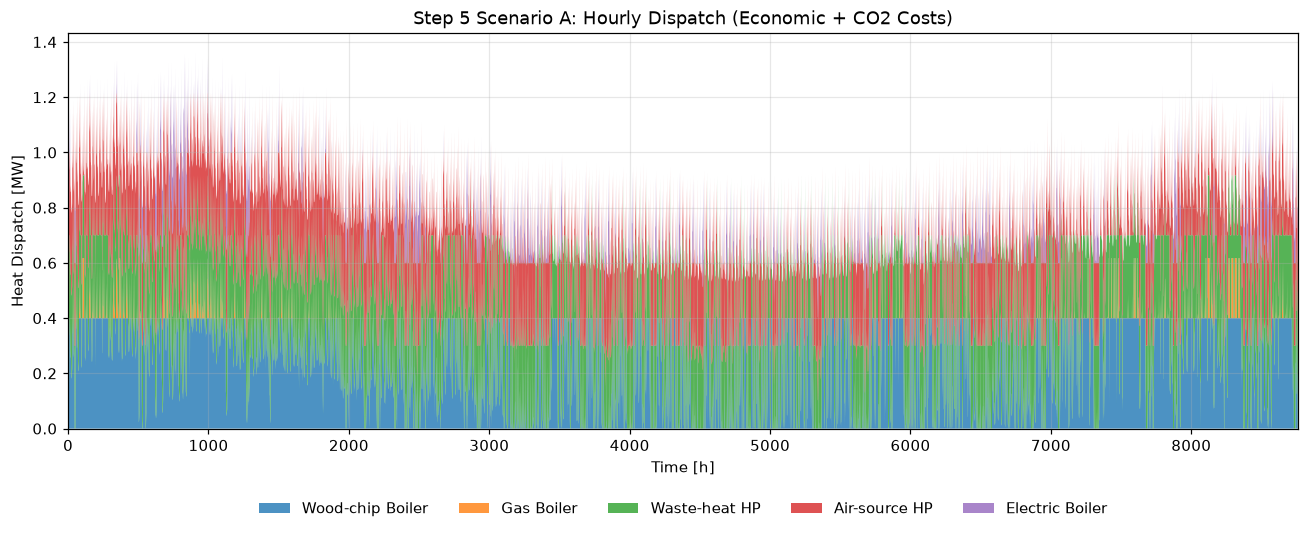

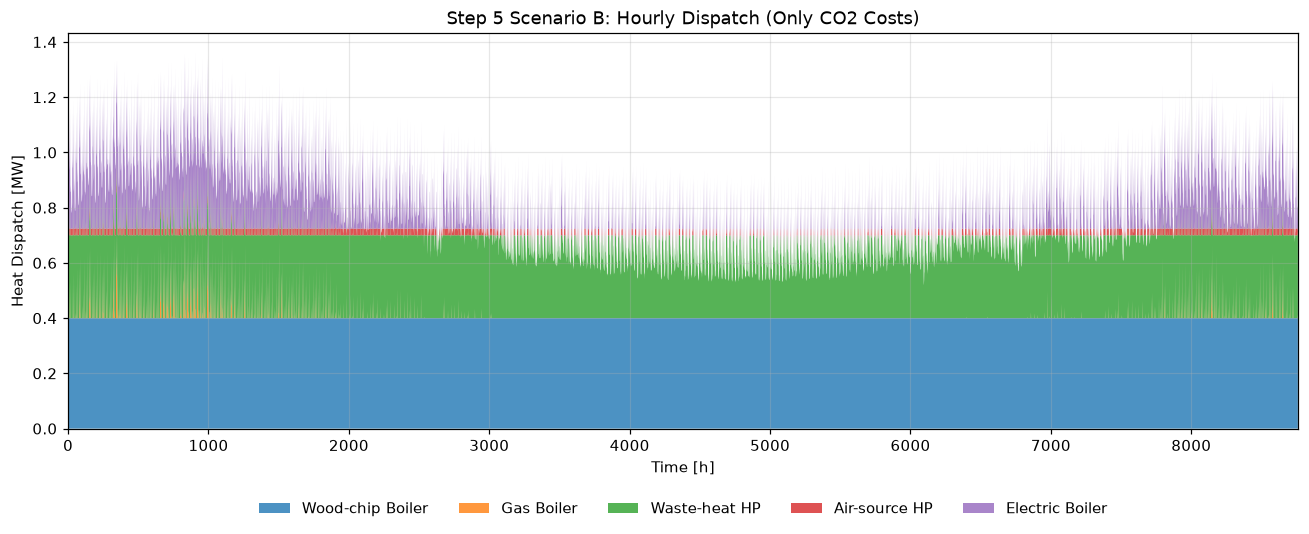

圖表已修正：X軸改為時間 [h] (0-8760)，並移除需求黑線。


In [26]:
# ── 修正：Step 4 與 Step 5 逐時調度圖表繪製 (X軸改為小時，移除需求線) ──
import matplotlib.pyplot as plt
import numpy as np

def plot_dispatch(dispatch_df, title, filename):
    fig, ax = plt.subplots(figsize=(12, 5))
    
    # 將 X 軸改為純數字小時 (0 到 8760)
    hours = np.arange(len(dispatch_df))
    
    # 定義機組顏色與標籤
    labels = ["Wood-chip Boiler", "Gas Boiler", "Waste-heat HP", "Air-source HP", "Electric Boiler"]
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
    
    # 繪製堆疊面積圖
    ax.stackplot(hours, 
                 dispatch_df["wood_chip_boiler"], 
                 dispatch_df["gas_boiler"], 
                 dispatch_df["waste_heat_hp"], 
                 dispatch_df["air_source_hp"], 
                 dispatch_df["electric_boiler"], 
                 labels=labels, colors=colors, alpha=0.8)
                 
    # 設定 SI 單位與標籤
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Time [h]", fontsize=10)
    ax.set_ylabel("Heat Dispatch [MW]", fontsize=10)
    
    # 設定 X 軸範圍為 0 到資料總筆數 (8760)
    ax.set_xlim(0, len(dispatch_df))
    
    # 調整圖例位置與樣式
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5, frameon=False)
    ax.grid(alpha=0.3)
    ax.margins(x=0)
    
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

# 繪製 Step 4 圖表
plot_dispatch(disp_s4_pri, "Step 4: Hourly Dispatch - Primary Scenario (Constant Price)", OUTPUT_DIR_S4 / "step4_dispatch_primary.png")
plot_dispatch(disp_s4_dk2, "Step 4: Hourly Dispatch - DK2 Scenario (Dynamic Price)", OUTPUT_DIR_S4 / "step4_dispatch_dk2.png")

# 繪製 Step 5 圖表
plot_dispatch(disp_s5A, "Step 5 Scenario A: Hourly Dispatch (Economic + CO2 Costs)", OUTPUT_DIR_S5 / "step5_dispatch_scenarioA.png")
plot_dispatch(disp_s5B, "Step 5 Scenario B: Hourly Dispatch (Only CO2 Costs)", OUTPUT_DIR_S5 / "step5_dispatch_scenarioB.png")

print("圖表已修正：X軸改為時間 [h] (0-8760)，並移除需求黑線。")